In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

print("Libraries imported")


Libraries imported


In [3]:
from pathlib import Path
import pandas as pd


DATA_DIR = Path("data")
if not (DATA_DIR / "LFB2018-2024.csv").exists():
    DATA_DIR = Path.cwd() / "LFB-Incident-Analysis" / "data"
if not (DATA_DIR / "LFB2018-2024.csv").exists():
    raise FileNotFoundError("Place the source files inside LFB-Incident-Analysis/data and run from that project folder.")


lfb_raw = pd.read_csv(
    DATA_DIR / "LFB2018-2024.csv"
)

population_raw = pd.read_csv(
    DATA_DIR / "LondonBoroughPopulationData.csv"
)

print("LFB dataset:", lfb_raw.shape)
print("Population dataset:", population_raw.shape)

print("\nLFB incident records:")
display(lfb_raw.head())

print("\nBorough population records:")
display(population_raw.head())


LFB dataset: (771311, 39)
Population dataset: (32, 2)

LFB incident records:


,IncidentNumber,DateOfCall,CalYear,TimeOfCall,HourOfCall,IncidentGroup,StopCodeDescription,SpecialServiceType,PropertyCategory,PropertyType,AddressQualifier,Postcode_full,Postcode_district,UPRN,USRN,IncGeo_BoroughCode,IncGeo_BoroughName,ProperCase,IncGeo_WardCode,IncGeo_WardName,IncGeo_WardNameNew,Easting_m,Northing_m,Easting_rounded,Northing_rounded,Latitude,Longitude,FRS,IncidentStationGround,FirstPumpArriving_AttendanceTime,FirstPumpArriving_DeployedFromStation,SecondPumpArriving_AttendanceTime,SecondPumpArriving_DeployedFromStation,NumStationsWithPumpsAttending,NumPumpsAttending,PumpCount,PumpMinutesRounded,Notional Cost (£),NumCalls
0,000008-01012018,01-Jan-18,2018,00:04:25,0,False Alarm,AFA,NaN,Non Residential,Mosque,Within same building,N2 8AY,N2,200220110,20013420,E09000003,BARNET,Barnet,E05013636,East Finchley,East Finchley,527184.0,189488.0,527150,189450,51.589900,-0.165453,London,Finchley,348.0,Finchley,NaN,NaN,1.0,1.0,1,60,328,1.0
1,000009-01012018,01-Jan-18,2018,00:04:30,0,False Alarm,AFA,NaN,Non Residential,Pub/wine bar/bar,Correct incident location,BR3 1ED,BR3,100022892766,20301747,E09000006,BROMLEY,Bromley,E05013987,Beckenham Town & Copers Cope,Beckenham Town & Copers Cope,537430.0,169565.0,537450,169550,51.408463,-0.025394,London,Beckenham,144.0,Beckenham,NaN,NaN,1.0,1.0,1,60,328,1.0
2,000010-01012018,01-Jan-18,2018,00:04:34,0,Fire,Secondary Fire,NaN,Outdoor Structure,Common external bin storage area,On land associated with building,N13 5SX,N13,207086892,20704500,E09000010,ENFIELD,Enfield,E05013683,Highfield,Highfield,531901.0,193161.0,531950,193150,51.621823,-0.096022,London,Edmonton,232.0,Southgate,NaN,NaN,1.0,1.0,1,60,328,1.0
3,000011-01012018,01-Jan-18,2018,00:04:58,0,Special Service,Special Service,RTC,Road Vehicle,Multiple Vehicles,In street outside gazetteer location,EN1 4LD,EN1,207153957,20702569,E09000010,ENFIELD,Enfield,E05013677,Carterhatch,Carterhatch,534799.0,197474.0,534750,197450,51.659894,-0.052524,London,Enfield,22.0,Enfield,NaN,NaN,1.0,1.0,1,60,328,1.0
4,000014-01012018,01-Jan-18,2018,00:07:47,0,Fire,Primary Fire,NaN,Road Vehicle,Car,In street outside gazetteer location,E15 1QY,E15,10023996788,22200068,E09000025,NEWHAM,Newham,E05013917,Maryland,Maryland,539451.0,185362.0,539450,185350,51.549924,0.009877,London,Stratford,241.0,Stratford,NaN,NaN,1.0,1.0,1,60,328,6.0



Borough population records:


,BoroughName,Population
0,Croydon,"397,741"
1,Barnet,"395,007"
2,Ealing,"375,340"
3,Newham,"362,552"
4,Brent,"344,521"


In [4]:
def data_quality_report(data, name):
    print(f"\n--- {name} ---")
    print(f"Rows: {data.shape[0]:,}")
    print(f"Columns: {data.shape[1]}")

    quality = pd.DataFrame({
        "Data Type": data.dtypes,
        "Missing Values": data.isna().sum(),
        "Missing (%)": data.isna().mean() * 100
    })

    display(quality.sort_values("Missing (%)", ascending=False).round(2))

    print("Fully duplicated rows:", data.duplicated().sum())



data_quality_report(lfb_raw, "LFB Incident Data")
data_quality_report(population_raw, "Borough Population Data")


print(
    "\nDuplicate IncidentNumbers:",
    lfb_raw["IncidentNumber"].duplicated().sum()
)



--- LFB Incident Data ---
Rows: 771,311
Columns: 39


,Data Type,Missing Values,Missing (%)
SpecialServiceType,str,499279,64.73
SecondPumpArriving_DeployedFromStation,str,488641,63.35
SecondPumpArriving_AttendanceTime,float64,488636,63.35
Postcode_full,str,426088,55.24
Northing_m,float64,426088,55.24
Longitude,float64,426088,55.24
Latitude,float64,426088,55.24
Easting_m,float64,426088,55.24
FirstPumpArriving_DeployedFromStation,str,43782,5.68
FirstPumpArriving_AttendanceTime,float64,43776,5.68


Fully duplicated rows: 0

--- Borough Population Data ---
Rows: 32
Columns: 2


,Data Type,Missing Values,Missing (%)
BoroughName,str,0,0.0
Population,str,0,0.0


Fully duplicated rows: 0

Duplicate IncidentNumbers: 0


In [5]:
lfb_clean = lfb_raw.copy()
population_clean = population_raw.copy()


lfb_clean["DateOfCall"] = pd.to_datetime(
    lfb_clean["DateOfCall"],
    format="%d-%b-%y",
    errors="coerce"
)


lfb_clean["IncGeo_BoroughName"] = (
    lfb_clean["IncGeo_BoroughName"]
    .str.strip()
    .str.upper()
)

population_clean["BoroughName"] = (
    population_clean["BoroughName"]
    .str.strip()
    .str.upper()
)


population_clean["Population"] = pd.to_numeric(
    population_clean["Population"]
    .astype(str)
    .str.replace(",", "", regex=False),
    errors="coerce"
)


print("Invalid dates:", lfb_clean["DateOfCall"].isna().sum())
print("Invalid populations:", population_clean["Population"].isna().sum())

print("\nDate range:")
print(lfb_clean["DateOfCall"].min())
print(lfb_clean["DateOfCall"].max())

print("\nPopulation data:")
display(population_clean.head())


Invalid dates: 0
Invalid populations: 0

Date range:
2018-01-01 00:00:00
2024-09-30 00:00:00

Population data:


,BoroughName,Population
0,CROYDON,397741
1,BARNET,395007
2,EALING,375340
3,NEWHAM,362552
4,BRENT,344521


In [6]:
print("Incident groups:")
display(lfb_clean["IncidentGroup"].value_counts(dropna=False))


resource_columns = [
    "NumPumpsAttending",
    "PumpCount",
    "PumpMinutesRounded",

]

print("\nResource summary:")
display(lfb_clean[resource_columns].describe().T)


print("\nMissing values:")
display(lfb_clean[resource_columns].isna().sum())


for col in resource_columns:
    print(f"\n{col}")
    print("Negative:", (lfb_clean[col] < 0).sum())
    print("Zero:", (lfb_clean[col] == 0).sum())


Incident groups:


IncidentGroup
False Alarm        381223
Special Service    272187
Fire               117895
NaN                     6
Name: count, dtype: int64


Resource summary:


,count,mean,std,min,25%,50%,75%,max
NumPumpsAttending,762860.0,1.550100,0.907413,1.0,1.0,1.0,2.0,14.0
PumpCount,771311.0,1.596522,1.481744,1.0,1.0,1.0,2.0,250.0
PumpMinutesRounded,771311.0,76.608369,311.439490,60.0,60.0,60.0,60.0,72157.0



Missing values:


NumPumpsAttending     8451
PumpCount                0
PumpMinutesRounded       0
dtype: int64


NumPumpsAttending
Negative: 0
Zero: 0

PumpCount
Negative: 0
Zero: 0

PumpMinutesRounded
Negative: 0
Zero: 0


In [7]:
pump_comparison = lfb_clean[
    ["NumPumpsAttending", "PumpCount", "PumpMinutesRounded"]
].copy()

print("Records where pump counts differ:")
print(
    (
        pump_comparison["NumPumpsAttending"].notna()
        &
        (
            pump_comparison["NumPumpsAttending"]
            != pump_comparison["PumpCount"]
        )
    ).sum()
)

print("\nMost common PumpCount values:")
display(lfb_clean["PumpCount"].value_counts().head(10))

print("\nMost common pump-minute values:")
display(lfb_clean["PumpMinutesRounded"].value_counts().head(10))

print("\nTen records with the highest PumpCount:")
display(
    lfb_clean.nlargest(10, "PumpCount")[
        [
            "IncidentNumber",
            "IncidentGroup",
            "NumPumpsAttending",
            "PumpCount",
            "PumpMinutesRounded",

        ]
    ]
)


Records where pump counts differ:
16821

Most common PumpCount values:


PumpCount
1     473049
2     228923
3      29728
5      25010
4       9934
6       2308
7        598
8        437
9        274
10       154
Name: count, dtype: int64


Most common pump-minute values:


PumpMinutesRounded
60    670212
62      2427
61      2385
63      2379
64      2199
65      2099
66      2093
67      2033
68      1886
69      1861
Name: count, dtype: int64


Ten records with the highest PumpCount:


,IncidentNumber,IncidentGroup,NumPumpsAttending,PumpCount,PumpMinutesRounded
156995,086232-05072019,Fire,1.0,250,72157
56356,096730-15072018,Fire,1.0,209,66113
10847,018108-12022018,Fire,4.0,198,59001
48058,080303-23062018,Fire,7.0,197,57433
757260,142563-26082024,Fire,6.0,189,60502
628117,137654-08092023,Fire,4.0,187,52685
143826,063499-23052019,Fire,2.0,179,49520
105915,181992-31122018,Fire,3.0,175,50374
355781,076095-20062021,Fire,2.0,156,39821
245454,057314-15052020,Fire,4.0,148,39848


In [8]:
pump_minimum = (
    lfb_clean.groupby("IncidentGroup")
    .agg(
        incidents=("IncidentNumber", "count"),
        exactly_60=("PumpMinutesRounded", lambda x: (x == 60).sum()),
        median_minutes=("PumpMinutesRounded", "median"),
        mean_minutes=("PumpMinutesRounded", "mean")
    )
)

pump_minimum["exactly_60_pct"] = (
    pump_minimum["exactly_60"]
    / pump_minimum["incidents"] * 100
)

display(pump_minimum.round(2))


,incidents,exactly_60,median_minutes,mean_minutes,exactly_60_pct
IncidentGroup,,,,,
False Alarm,381223,352042,60.0,62.66,92.35
Fire,117895,82467,60.0,138.63,69.95
Special Service,272187,235697,60.0,69.29,86.59


In [9]:
lfb_analysis = lfb_clean.copy()


lfb_analysis["Year"] = lfb_analysis["DateOfCall"].dt.year
lfb_analysis["Month"] = lfb_analysis["DateOfCall"].dt.month
lfb_analysis["Hour"] = lfb_analysis["HourOfCall"]


lfb_analysis["RecordedPumpHours"] = (
    lfb_analysis["PumpMinutesRounded"] / 60
)


lfb_classified = lfb_analysis[
    lfb_analysis["IncidentGroup"].notna()
].copy()

print("All incident records:", len(lfb_analysis))
print("Classified incidents:", len(lfb_classified))

print("\nDate range:")
print(lfb_analysis["DateOfCall"].min())
print(lfb_analysis["DateOfCall"].max())

print("\nRecorded pump-hours summary:")
display(lfb_classified["RecordedPumpHours"].describe())


All incident records: 771311
Classified incidents: 771305

Date range:
2018-01-01 00:00:00
2024-09-30 00:00:00

Recorded pump-hours summary:


count    771305.000000
mean          1.276808
std           5.190678
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        1202.616667
Name: RecordedPumpHours, dtype: float64

In [10]:
borough_demand = (
    lfb_classified
    .groupby("IncGeo_BoroughName")
    .agg(
        Total_Incidents=("IncidentNumber", "count"),
        Total_Pump_Hours=("RecordedPumpHours", "sum"),

    )
    .sort_values("Total_Incidents", ascending=False)
)

print("Top 10 boroughs by recorded incident count:")

display(
    borough_demand.head(10).round(2)
)


Top 10 boroughs by recorded incident count:


,Total_Incidents,Total_Pump_Hours
IncGeo_BoroughName,,
WESTMINSTER,55847,67775.02
CAMDEN,34135,40320.60
SOUTHWARK,33395,39377.07
TOWER HAMLETS,33171,41314.02
LAMBETH,32673,39297.10
CROYDON,31725,40507.90
HACKNEY,30264,36171.88
LEWISHAM,27926,33072.62
BARNET,26637,33298.47


In [11]:
complete_years = lfb_classified[
    lfb_classified["Year"].between(2018, 2023)
].copy()


annual_borough_demand = (
    complete_years.groupby("IncGeo_BoroughName")
    .agg(Total_Incidents=("IncidentNumber", "count"))
    .reset_index()
)


annual_borough_demand["Annual_Avg_Incidents"] = (
    annual_borough_demand["Total_Incidents"] / 6
)


borough_population_kpis = annual_borough_demand.merge(
    population_clean,
    left_on="IncGeo_BoroughName",
    right_on="BoroughName",
    how="left",
    validate="one_to_one"
)


borough_population_kpis["Incidents_per_1000"] = (
    borough_population_kpis["Annual_Avg_Incidents"]
    / borough_population_kpis["Population"] * 1000
)

print("Boroughs without population data:")
display(
    borough_population_kpis.loc[
        borough_population_kpis["Population"].isna(),
        ["IncGeo_BoroughName", "Total_Incidents"]
    ]
)

print("\nTop 10 boroughs by annual incidents per 1,000 residents:")
display(
    borough_population_kpis
    .dropna(subset=["Population"])
    .sort_values("Incidents_per_1000", ascending=False)
    [
        ["IncGeo_BoroughName", "Annual_Avg_Incidents",
         "Population", "Incidents_per_1000"]
    ]
    .head(10)
    .round(2)
)


Boroughs without population data:


,IncGeo_BoroughName,Total_Incidents
6,CITY OF LONDON,6676



Top 10 boroughs by annual incidents per 1,000 residents:


,IncGeo_BoroughName,Annual_Avg_Incidents,Population,Incidents_per_1000
32,WESTMINSTER,8137.17,211508.0,38.47
19,KENSINGTON AND CHELSEA,3735.17,147460.0,25.33
5,CAMDEN,5002.83,220903.0,22.65
12,HAMMERSMITH AND FULHAM,3151.33,186176.0,16.93
18,ISLINGTON,3693.33,220584.0,16.74
11,HACKNEY,4388.00,263282.0,16.67
27,SOUTHWARK,4843.67,315519.0,15.35
21,LAMBETH,4699.33,315706.0,14.89
29,TOWER HAMLETS,4785.83,328626.0,14.56
22,LEWISHAM,4015.67,298708.0,13.44


In [12]:
import geopandas as gpd


uk_boundaries = gpd.read_file(
    DATA_DIR / "london_boundaries.geojson"
)


london_boundaries = uk_boundaries[
    uk_boundaries["LAD23CD"].str.startswith("E09")
].copy()


london_boundaries["BoroughName"] = (
    london_boundaries["LAD23NM"]
    .str.strip()
    .str.upper()
)

print("Total UK local authorities:", len(uk_boundaries))
print("London areas:", len(london_boundaries))
print("Coordinate system:", london_boundaries.crs)

display(london_boundaries[["LAD23CD", "BoroughName"]].head(10))


Total UK local authorities: 361
London areas: 33
Coordinate system: EPSG:27700


,LAD23CD,BoroughName
263,E09000001,CITY OF LONDON
264,E09000002,BARKING AND DAGENHAM
265,E09000003,BARNET
266,E09000004,BEXLEY
267,E09000005,BRENT
268,E09000006,BROMLEY
269,E09000007,CAMDEN
270,E09000008,CROYDON
271,E09000009,EALING
272,E09000010,ENFIELD


In [13]:
london_map = london_boundaries.merge(
    borough_population_kpis[
        ["IncGeo_BoroughName", "Annual_Avg_Incidents",
         "Population", "Incidents_per_1000"]
    ],
    left_on="BoroughName",
    right_on="IncGeo_BoroughName",
    how="left",
    validate="one_to_one",
    indicator=True
)


print("Merge results:")
display(london_map["_merge"].value_counts())

print("\nAreas without population-adjusted incident rates:")
display(
    london_map.loc[
        london_map["Incidents_per_1000"].isna(),
        ["BoroughName", "Population", "_merge"]
    ]
)

print("\nFinal map dataset:")
display(
    london_map[
        ["BoroughName", "Annual_Avg_Incidents",
         "Population", "Incidents_per_1000"]
    ].head()
)


Merge results:


_merge
both          33
left_only      0
right_only     0
Name: count, dtype: int64


Areas without population-adjusted incident rates:


,BoroughName,Population,_merge
0,CITY OF LONDON,NaN,both



Final map dataset:


,BoroughName,Annual_Avg_Incidents,Population,Incidents_per_1000
0,CITY OF LONDON,1112.666667,NaN,NaN
1,BARKING AND DAGENHAM,2147.166667,222308.0,9.658522
2,BARNET,3869.166667,395007.0,9.795185
3,BEXLEY,2358.166667,250853.0,9.400592
4,BRENT,3531.000000,344521.0,10.249012


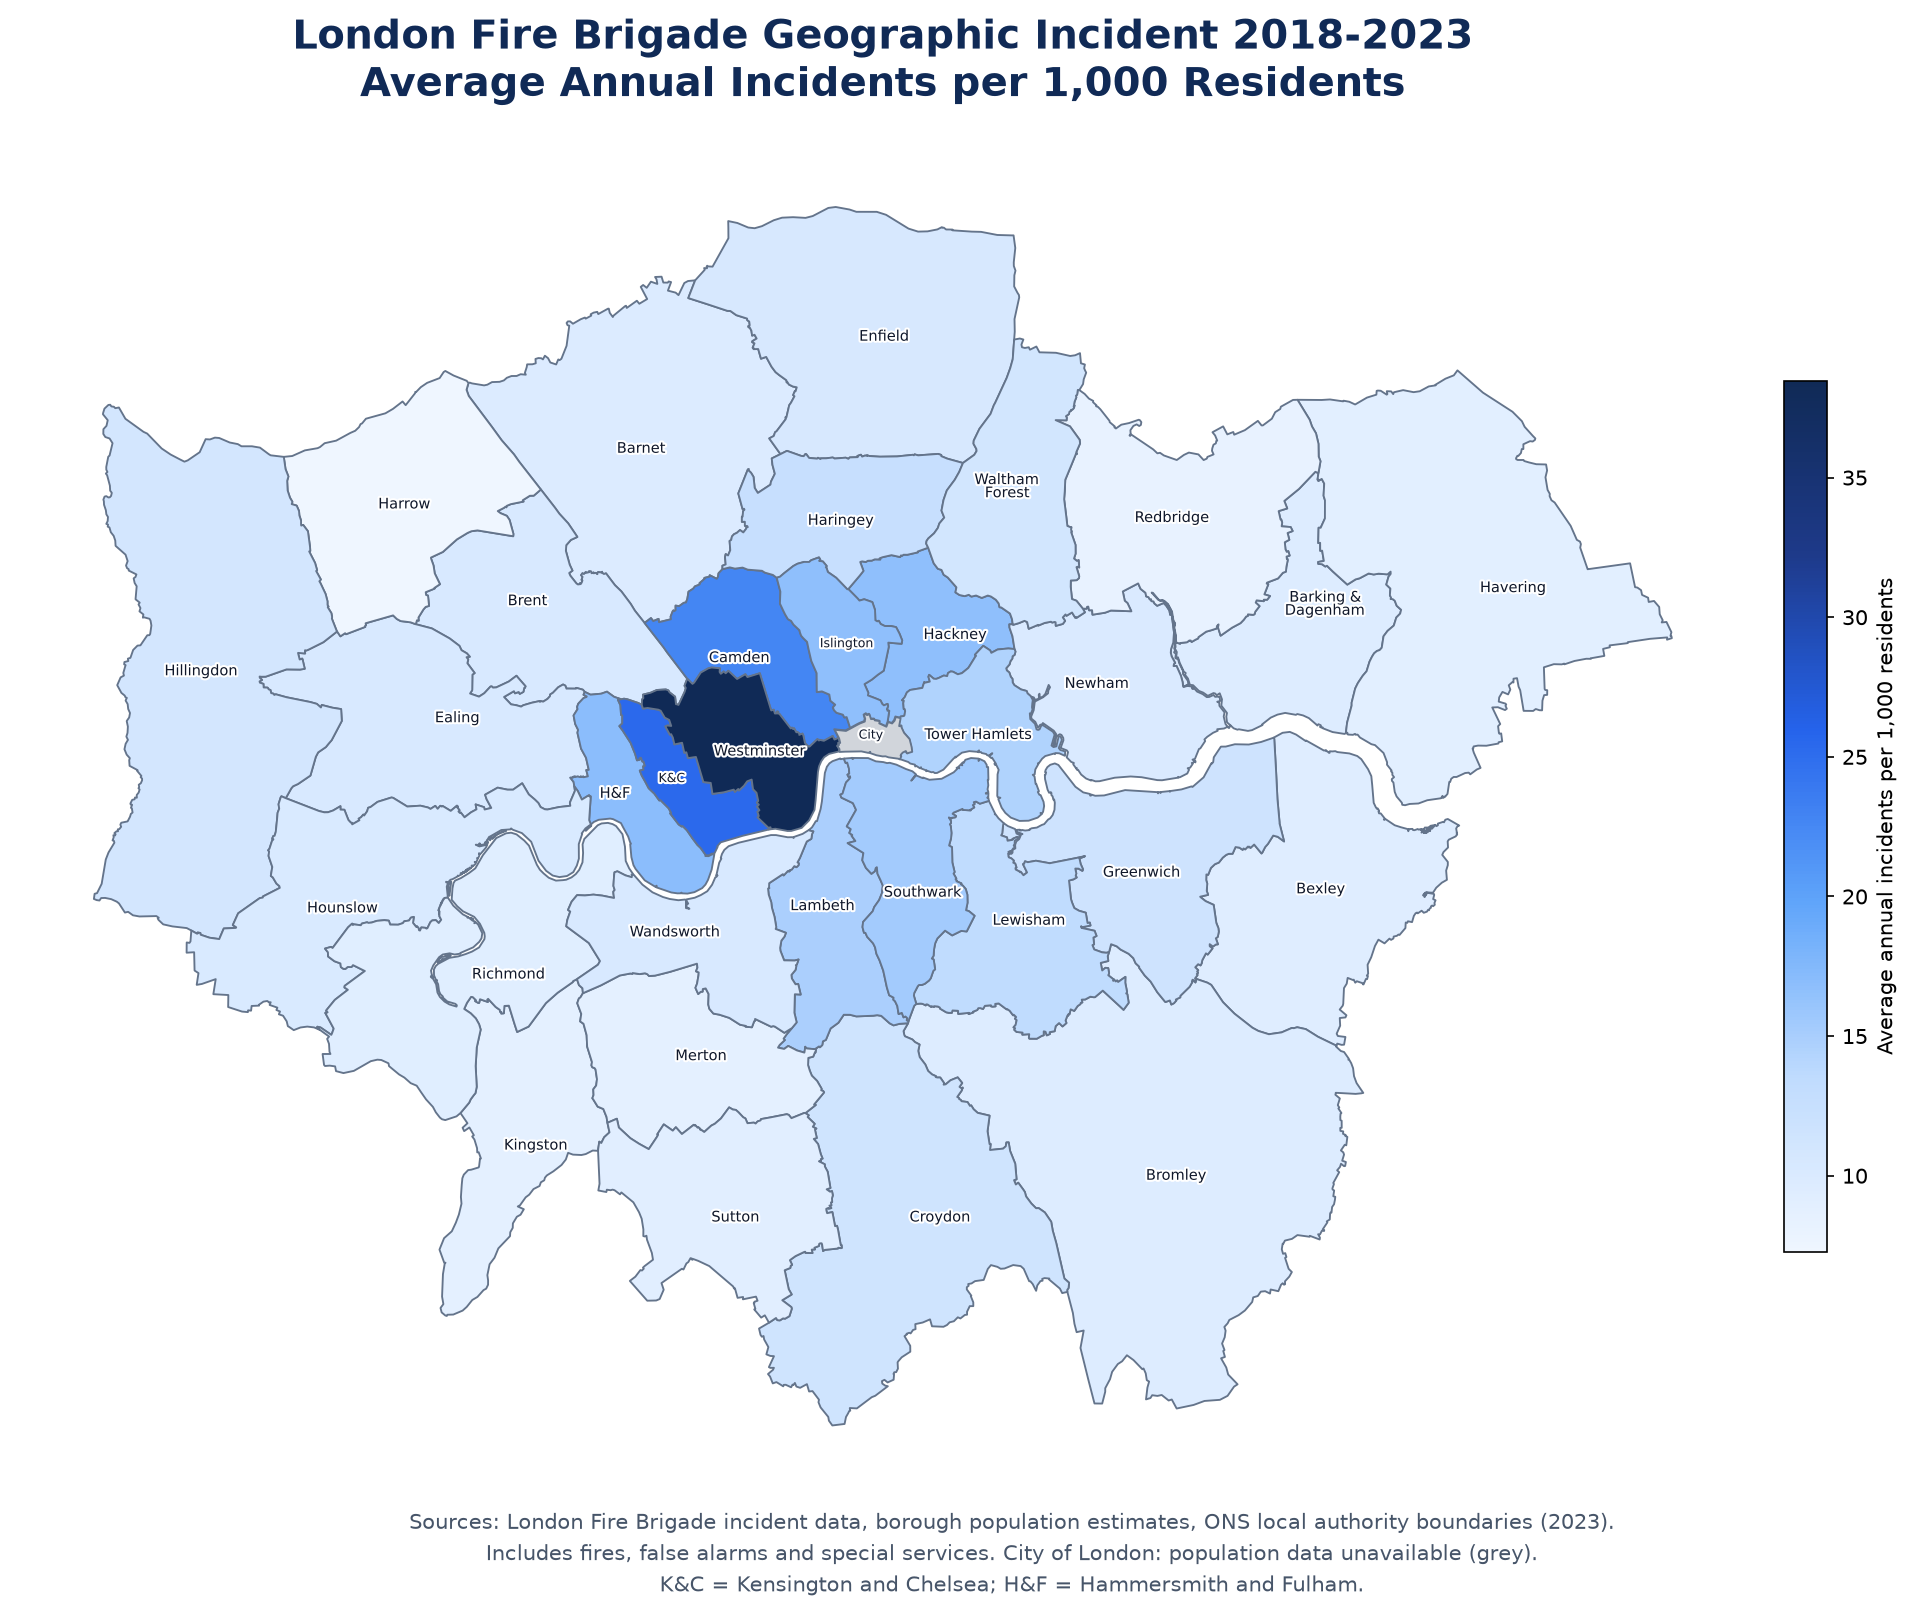

Map saved successfully: figures\london_incident_demand_map.png


In [14]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap


figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


blue_cmap = LinearSegmentedColormap.from_list(
    "LondonBlue",
    [
        "#EFF6FF",
        "#BFDBFE",
        "#60A5FA",
        "#2563EB",
        "#1E3A8A",
        "#102A56"
    ]
)



fig, ax = plt.subplots(figsize=(15, 11), dpi=150)

london_map.plot(
    column="Incidents_per_1000",
    cmap=blue_cmap,
    linewidth=0.9,
    edgecolor="#64748B",
    legend=True,
    legend_kwds={
        "label": "Average annual incidents per 1,000 residents",
        "shrink": 0.65,
        "pad": 0.015
    },
    missing_kwds={
        "color": "#D1D5DB",
        "edgecolor": "#64748B"
    },
    ax=ax
)


short_names = {
    "KENSINGTON AND CHELSEA": "K&C",
    "HAMMERSMITH AND FULHAM": "H&F",
    "BARKING AND DAGENHAM": "Barking &\nDagenham",
    "KINGSTON UPON THAMES": "Kingston",
    "RICHMOND UPON THAMES": "Richmond",
    "CITY OF LONDON": "City",
    "WESTMINSTER": "Westminster",
    "WALTHAM FOREST": "Waltham\nForest"
}



for _, borough in london_map.iterrows():


    point = borough.geometry.representative_point()


    name = short_names.get(
        borough["BoroughName"],
        borough["BoroughName"].title()
    )


    area = borough.geometry.area

    fontsize = 6 if area < 15_000_000 else 7

    ax.text(
        point.x,
        point.y,
        name,
        fontsize=fontsize,
        ha="center",
        va="center",
        color="#0F172A",
        fontweight="normal",
        linespacing=0.9,
        path_effects=[
            pe.withStroke(
                linewidth=2,
                foreground="white"
            )
        ],
        zorder=5
    )



ax.set_title(
    "London Fire Brigade Geographic Incident 2018-2023\n"
    "Average Annual Incidents per 1,000 Residents",
    fontsize=19,
    fontweight="bold",
    color="#102A56",
    pad=24
)

ax.set_axis_off()



fig.text(
    0.5,
    0.035,
    "Sources: London Fire Brigade incident data, borough population estimates, "
    "ONS local authority boundaries (2023).\n"
    "Includes fires, false alarms and special services. "
    "City of London: population data unavailable (grey).\n"
    "K&C = Kensington and Chelsea; H&F = Hammersmith and Fulham.",
    ha="center",
    fontsize=10,
    color="#475569",
    linespacing=1.5
)



plt.tight_layout(rect=[0, 0.085, 1, 0.96])



output_path = figures_dir / "london_incident_demand_map.png"

fig.savefig(
    output_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Map saved successfully: {output_path}")


In [15]:
fire_incidents = complete_years[
    lfb_classified["IncidentGroup"] == "Fire"
].copy()


fire_borough = (
    fire_incidents
    .groupby("IncGeo_BoroughName")
    .agg(Fire_Incidents=("IncidentNumber", "count"))
    .reset_index()
)


fire_borough = fire_borough.merge(
    population_clean,
    left_on="IncGeo_BoroughName",
    right_on="BoroughName",
    how="left",
    validate="one_to_one"
)


fire_borough["Fires_per_1000"] = (
    fire_borough["Fire_Incidents"] / 6
    / fire_borough["Population"]
    * 1000
)


fire_map = london_boundaries.merge(
    fire_borough[
        ["IncGeo_BoroughName", "Fire_Incidents", "Fires_per_1000"]
    ],
    left_on="BoroughName",
    right_on="IncGeo_BoroughName",
    how="left",
    validate="one_to_one",
    indicator=True
)


print("Total recorded fires:", len(fire_incidents))
print("\nBoundary merge:")
print(fire_map["_merge"].value_counts())

print("\nAreas without population-adjusted fire rates:")
display(
    fire_map.loc[
        fire_map["Fires_per_1000"].isna(),
        ["BoroughName", "Fire_Incidents"]
    ]
)

print("\nTop 10 boroughs by average annual fires per 1,000 residents:")
display(
    fire_map
    .dropna(subset=["Fires_per_1000"])
    .sort_values("Fires_per_1000", ascending=False)
    [["BoroughName", "Fire_Incidents", "Fires_per_1000"]]
    .head(10)
    .round(2)
)


Total recorded fires: 105359

Boundary merge:
_merge
both          33
left_only      0
right_only     0
Name: count, dtype: int64

Areas without population-adjusted fire rates:


C:\Users\Rakeen Afser\AppData\Local\Temp\ipykernel_16184\2062882249.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  fire_incidents = complete_years[


,BoroughName,Fire_Incidents
0,CITY OF LONDON,438



Top 10 boroughs by average annual fires per 1,000 residents:


,BoroughName,Fire_Incidents,Fires_per_1000
32,WESTMINSTER,4550,3.59
10,GREENWICH,4215,2.39
30,WALTHAM FOREST,3824,2.31
17,HOUNSLOW,3992,2.25
16,HILLINGDON,4285,2.24
6,CAMDEN,2960,2.23
29,TOWER HAMLETS,4355,2.21
3,BEXLEY,3299,2.19
9,ENFIELD,4209,2.14
1,BARKING AND DAGENHAM,2802,2.10


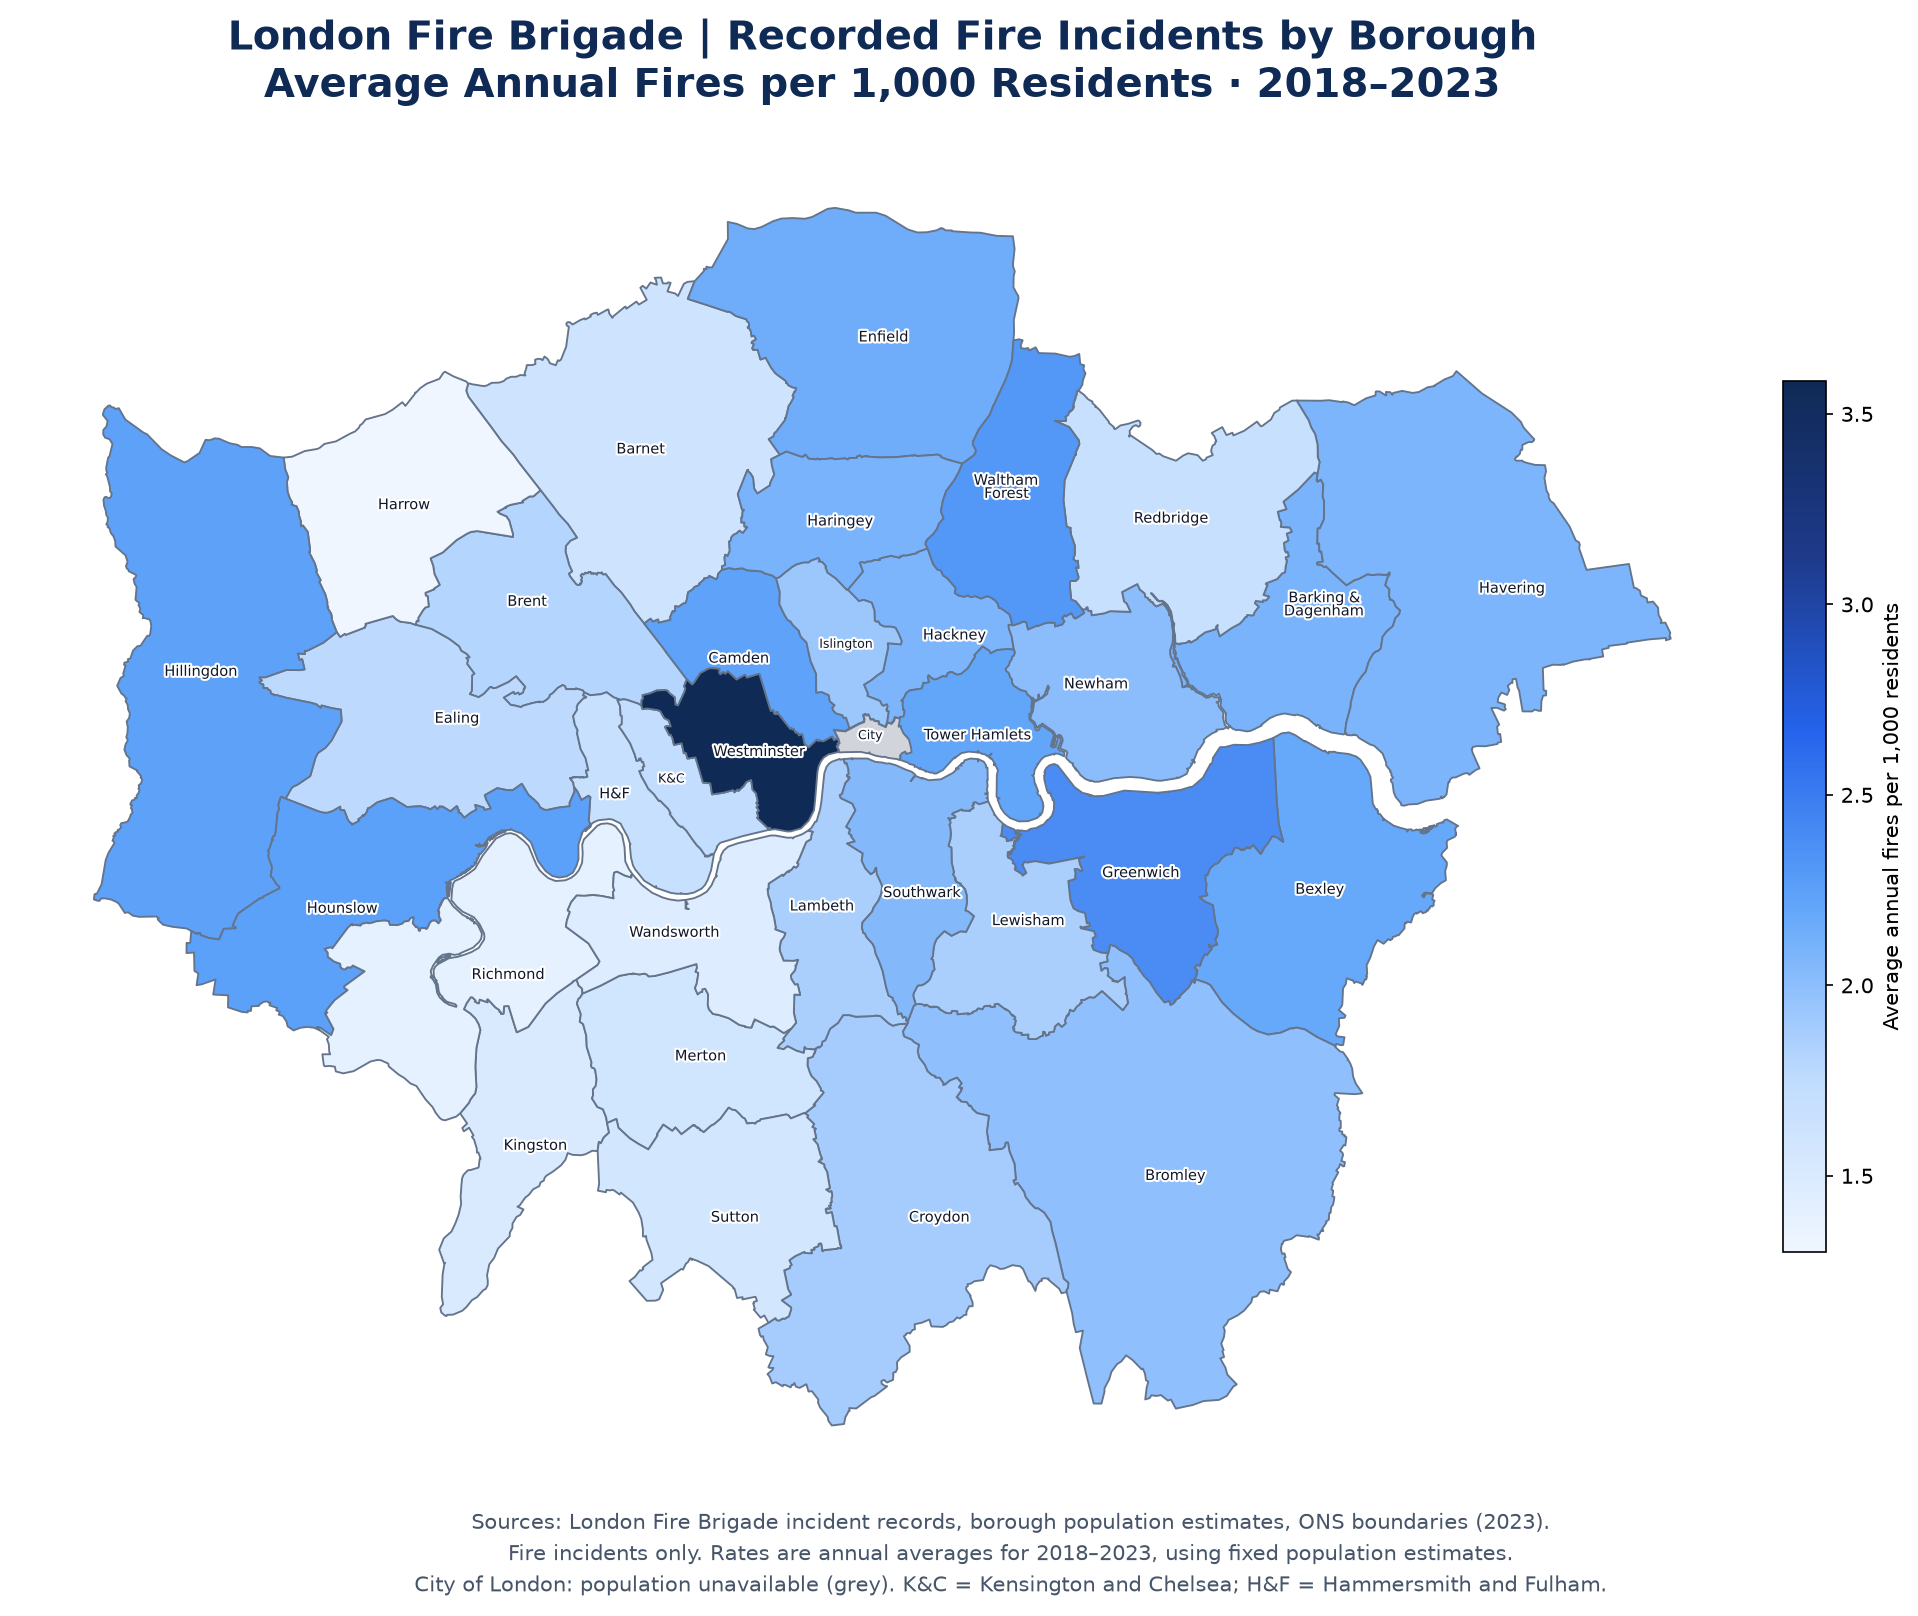

Map saved successfully: figures\london_fire_only_map.png


In [16]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


blue_cmap = LinearSegmentedColormap.from_list(
    "LondonBlue",
    ["#EFF6FF", "#BFDBFE", "#60A5FA",
     "#2563EB", "#1E3A8A", "#102A56"]
)

fig, ax = plt.subplots(figsize=(15, 11), dpi=150)


fire_map.plot(
    column="Fires_per_1000",
    cmap=blue_cmap,
    linewidth=0.9,
    edgecolor="#64748B",
    legend=True,
    legend_kwds={
        "label": "Average annual fires per 1,000 residents",
        "shrink": 0.65,
        "pad": 0.015
    },
    missing_kwds={
        "color": "#D1D5DB",
        "edgecolor": "#64748B"
    },
    ax=ax
)


short_names = {
    "KENSINGTON AND CHELSEA": "K&C",
    "HAMMERSMITH AND FULHAM": "H&F",
    "BARKING AND DAGENHAM": "Barking &\nDagenham",
    "KINGSTON UPON THAMES": "Kingston",
    "RICHMOND UPON THAMES": "Richmond",
    "CITY OF LONDON": "City",
    "WALTHAM FOREST": "Waltham\nForest"
}


for _, borough in fire_map.iterrows():

    point = borough.geometry.representative_point()

    name = short_names.get(
        borough["BoroughName"],
        borough["BoroughName"].title()
    )

    area = borough.geometry.area
    fontsize = 6 if area < 15_000_000 else 7

    ax.text(
        point.x,
        point.y,
        name,
        fontsize=fontsize,
        ha="center",
        va="center",
        color="#0F172A",
        fontweight="normal",
        linespacing=0.9,
        path_effects=[
            pe.withStroke(
                linewidth=2,
                foreground="white"
            )
        ],
        zorder=5
    )


ax.set_title(
    "London Fire Brigade | Recorded Fire Incidents by Borough\n"
    "Average Annual Fires per 1,000 Residents · 2018–2023",
    fontsize=19,
    fontweight="bold",
    color="#102A56",
    pad=24
)

ax.set_axis_off()


fig.text(
    0.5, 0.035,
    "Sources: London Fire Brigade incident records, borough population estimates, "
    "ONS boundaries (2023).\n"
    "Fire incidents only. Rates are annual averages for 2018–2023, "
    "using fixed population estimates.\n"
    "City of London: population unavailable (grey). "
    "K&C = Kensington and Chelsea; H&F = Hammersmith and Fulham.",
    ha="center",
    fontsize=10,
    color="#475569",
    linespacing=1.5
)

plt.tight_layout(rect=[0, 0.085, 1, 0.96])


output_path = figures_dir / "london_fire_only_map.png"

fig.savefig(
    output_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Map saved successfully: {output_path}")


In [17]:
fire_ranking = (
    fire_map
    .dropna(subset=["Fires_per_1000"])
    .sort_values("Fires_per_1000", ascending=False)
    [
        ["BoroughName", "Fire_Incidents", "Fires_per_1000"]
    ]
)

print("Top 10 boroughs by average annual fire rate:")
display(fire_ranking.head(10).round(2))

print("\nBottom 5 boroughs by average annual fire rate:")
display(fire_ranking.tail(5).round(2))

print("\nTotal recorded fire incidents:")
print(f"{len(fire_incidents):,}")


Top 10 boroughs by average annual fire rate:


,BoroughName,Fire_Incidents,Fires_per_1000
32,WESTMINSTER,4550,3.59
10,GREENWICH,4215,2.39
30,WALTHAM FOREST,3824,2.31
17,HOUNSLOW,3992,2.25
16,HILLINGDON,4285,2.24
6,CAMDEN,2960,2.23
29,TOWER HAMLETS,4355,2.21
3,BEXLEY,3299,2.19
9,ENFIELD,4209,2.14
1,BARKING AND DAGENHAM,2802,2.10



Bottom 5 boroughs by average annual fire rate:


,BoroughName,Fire_Incidents,Fires_per_1000
28,SUTTON,2005,1.58
20,KINGSTON UPON THAMES,1541,1.51
31,WANDSWORTH,2919,1.47
26,RICHMOND UPON THAMES,1638,1.40
14,HARROW,2055,1.30



Total recorded fire incidents:
105,359


In [18]:
incident_composition = (
    complete_years
    .groupby(["IncGeo_BoroughName", "IncidentGroup"])
    .size()
    .unstack(fill_value=0)
)


incident_composition["Total"] = incident_composition.sum(axis=1)


incident_composition_pct = (
    incident_composition
    .drop(columns="Total")
    .div(incident_composition["Total"], axis=0)
    * 100
)


top_borough_names = (
    borough_population_kpis
    .dropna(subset=["Incidents_per_1000"])
    .nlargest(10, "Incidents_per_1000")["IncGeo_BoroughName"]
    .tolist()
)


top_composition = incident_composition_pct.loc[top_borough_names]

print("Incident composition (%) in the 10 highest-rate boroughs:")
display(top_composition.round(2))

print("\nRecorded incident counts:")
display(
    incident_composition.loc[top_borough_names]
)


Incident composition (%) in the 10 highest-rate boroughs:


IncidentGroup,False Alarm,Fire,Special Service
IncGeo_BoroughName,,,
WESTMINSTER,66.38,9.32,24.30
KENSINGTON AND CHELSEA,59.15,6.82,34.03
CAMDEN,58.85,9.86,31.29
HAMMERSMITH AND FULHAM,57.84,9.91,32.25
ISLINGTON,51.14,11.51,37.35
HACKNEY,44.14,12.50,43.35
SOUTHWARK,47.69,13.33,38.98
LAMBETH,47.01,12.49,40.50
TOWER HAMLETS,44.26,15.17,40.57



Recorded incident counts:


IncidentGroup,False Alarm,Fire,Special Service,Total
IncGeo_BoroughName,,,,
WESTMINSTER,32411,4550,11862,48823
KENSINGTON AND CHELSEA,13257,1528,7626,22411
CAMDEN,17664,2960,9393,30017
HAMMERSMITH AND FULHAM,10937,1874,6097,18908
ISLINGTON,11333,2551,8276,22160
HACKNEY,11622,3292,11414,26328
SOUTHWARK,13861,3873,11328,29062
LAMBETH,13256,3522,11418,28196
TOWER HAMLETS,12709,4355,11651,28715


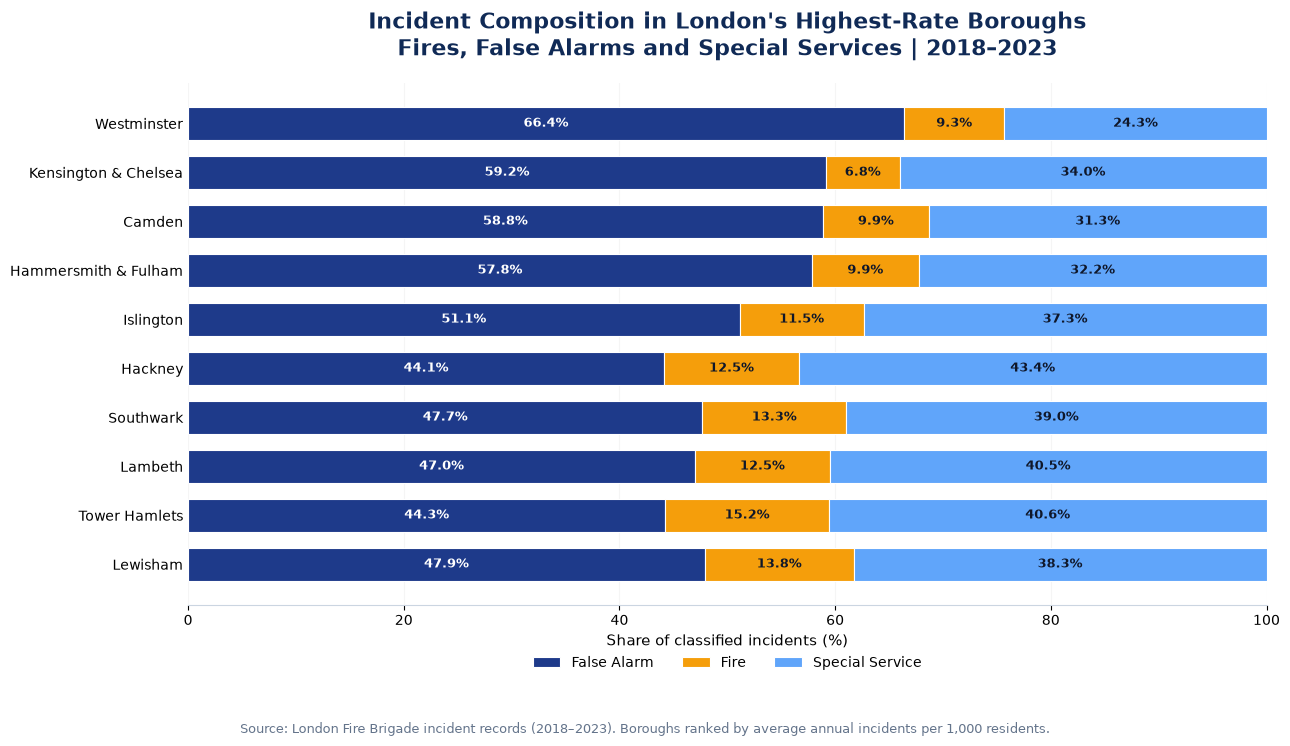

Chart saved to figures/borough_incident_composition.png


In [19]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


chart_data = top_composition.copy()

chart_data.index = (
    chart_data.index
    .str.title()
    .str.replace(" And ", " & ", regex=False)
)


category_colours = {
    "False Alarm": "#1E3A8A",
    "Fire": "#F59E0B",
    "Special Service": "#60A5FA"
}

fig, ax = plt.subplots(figsize=(13, 7.5))

left = np.zeros(len(chart_data))


for category in ["False Alarm", "Fire", "Special Service"]:

    values = chart_data[category].to_numpy()

    bars = ax.barh(
        chart_data.index,
        values,
        left=left,
        height=0.68,
        color=category_colours[category],
        label=category,
        edgecolor="white",
        linewidth=0.8
    )


    for bar, value in zip(bars, values):
        if value >= 6:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_y() + bar.get_height() / 2,
                f"{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
                fontweight="bold",
                color="white" if category == "False Alarm" else "#0F172A"
            )

    left += values


ax.invert_yaxis()

ax.set_xlim(0, 100)
ax.set_xlabel("Share of classified incidents (%)", fontsize=11)

ax.set_title(
    "Incident Composition in London's Highest-Rate Boroughs\n"
    "Fires, False Alarms and Special Services | 2018–2023",
    fontsize=16,
    fontweight="bold",
    color="#102A56",
    pad=20
)

ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, -0.15),
    ncol=3,
    frameon=False
)


for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)

ax.spines["bottom"].set_color("#CBD5E1")
ax.tick_params(axis="y", length=0)

ax.grid(axis="x", alpha=0.12)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.015,
    "Source: London Fire Brigade incident records (2018–2023). "
    "Boroughs ranked by average annual incidents per 1,000 residents.",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

fig.savefig(
    figures_dir / "borough_incident_composition.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to figures/borough_incident_composition.png")


In [20]:
annual_incidents = (
    complete_years
    .groupby(["Year", "IncidentGroup"])
    .size()
    .unstack(fill_value=0)
)


annual_incidents["Total"] = annual_incidents.sum(axis=1)

print("Annual incident counts by category:")
display(annual_incidents)


annual_growth = annual_incidents.pct_change() * 100

print("\nYear-on-year change (%):")
display(annual_growth.round(2))


Annual incident counts by category:


IncidentGroup,False Alarm,Fire,Special Service,Total
Year,,,,
2018,52856,19661,33457,105974
2019,53985,17982,33043,105010
2020,50187,17401,30980,98568
2021,53474,14923,41180,109577
2022,59403,19281,46708,125392
2023,62978,16111,47383,126472



Year-on-year change (%):


IncidentGroup,False Alarm,Fire,Special Service,Total
Year,,,,
2018,NaN,NaN,NaN,NaN
2019,2.14,-8.54,-1.24,-0.91
2020,-7.04,-3.23,-6.24,-6.13
2021,6.55,-14.24,32.92,11.17
2022,11.09,29.20,13.42,14.43
2023,6.02,-16.44,1.45,0.86


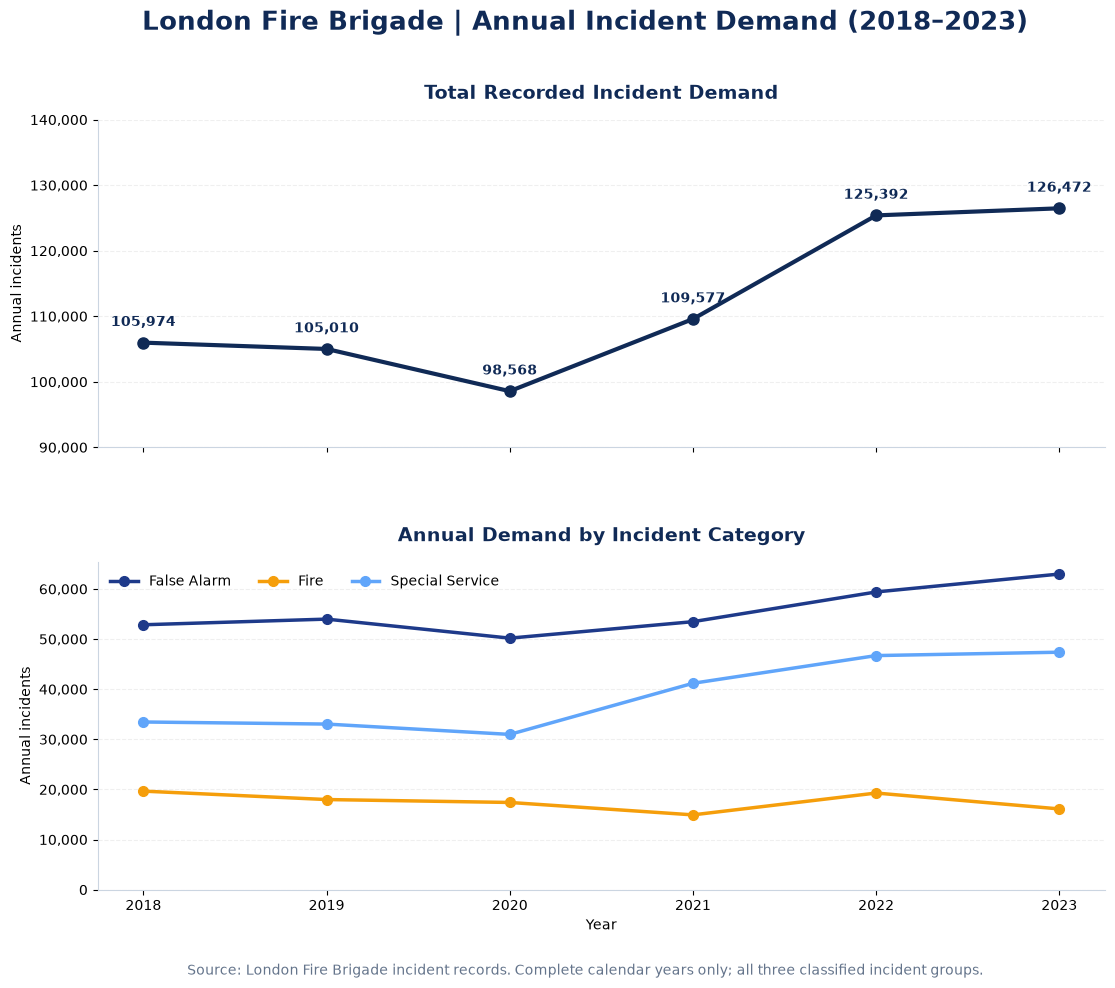

Chart saved to figures/annual_incident_trends.png


In [21]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


colours = {
    "Total": "#102A56",
    "False Alarm": "#1E3A8A",
    "Fire": "#F59E0B",
    "Special Service": "#60A5FA"
}

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 10),
    sharex=True,
    gridspec_kw={"hspace": 0.35}
)





axes[0].plot(
    annual_incidents.index,
    annual_incidents["Total"],
    marker="o",
    markersize=8,
    linewidth=3,
    color=colours["Total"]
)

for year, value in annual_incidents["Total"].items():
    axes[0].annotate(
        f"{value:,}",
        (year, value),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=colours["Total"]
    )

axes[0].set_title(
    "Total Recorded Incident Demand",
    fontsize=14,
    fontweight="bold",
    color="#102A56",
    pad=15
)

axes[0].set_ylabel("Annual incidents")
axes[0].set_ylim(90000, 140000)





for category in ["False Alarm", "Fire", "Special Service"]:

    axes[1].plot(
        annual_incidents.index,
        annual_incidents[category],
        marker="o",
        markersize=7,
        linewidth=2.5,
        label=category,
        color=colours[category]
    )

axes[1].set_title(
    "Annual Demand by Incident Category",
    fontsize=14,
    fontweight="bold",
    color="#102A56",
    pad=15
)

axes[1].set_ylabel("Annual incidents")
axes[1].set_xlabel("Year")
axes[1].legend(frameon=False, ncol=3, loc="upper left")
axes[1].set_ylim(bottom=0)





for ax in axes:
    ax.set_xticks(annual_incidents.index)
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda x, pos: f"{x:,.0f}")
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.2
    )
    ax.set_axisbelow(True)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

fig.suptitle(
    "London Fire Brigade | Annual Incident Demand (2018–2023)",
    fontsize=19,
    fontweight="bold",
    color="#102A56",
    y=0.99
)

fig.text(
    0.5, 0.025,
    "Source: London Fire Brigade incident records. "
    "Complete calendar years only; all three classified incident groups.",
    ha="center",
    fontsize=10,
    color="#64748B"
)

fig.savefig(
    figures_dir / "annual_incident_trends.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to figures/annual_incident_trends.png")


In [22]:
import calendar
import pandas as pd


monthly_counts = (
    complete_years
    .groupby(["Month", "IncidentGroup"])
    .size()
    .unstack(fill_value=0)
)



days_by_month = pd.Series(
    {
        month: sum(
            calendar.monthrange(year, month)[1]
            for year in range(2018, 2024)
        )
        for month in range(1, 13)
    },
    name="Days"
)


monthly_daily_average = monthly_counts.div(
    days_by_month,
    axis=0
)


monthly_daily_average["Total"] = (
    monthly_daily_average.sum(axis=1)
)


monthly_daily_average.index = [
    calendar.month_abbr[m]
    for m in monthly_daily_average.index
]

print("Average daily incidents by calendar month (2018–2023):")
display(monthly_daily_average.round(2))


print("\nHighest average daily demand by category:")

for category in ["Fire", "False Alarm", "Special Service", "Total"]:
    peak_month = monthly_daily_average[category].idxmax()
    peak_value = monthly_daily_average[category].max()

    print(f"{category}: {peak_month} ({peak_value:.2f} incidents/day)")


Average daily incidents by calendar month (2018–2023):


IncidentGroup,False Alarm,Fire,Special Service,Total
Jan,139.46,37.87,91.44,268.77
Feb,143.36,40.22,102.83,286.41
Mar,140.38,41.73,99.03,281.14
Apr,137.46,52.38,90.77,280.61
May,143.91,53.79,100.52,298.22
Jun,151.01,59.27,111.97,322.24
Jul,158.30,69.24,119.96,347.50
Aug,155.96,56.48,112.27,324.72
Sep,162.25,48.96,109.08,320.29
Oct,168.49,40.77,109.97,319.23



Highest average daily demand by category:
Fire: Jul (69.24 incidents/day)
False Alarm: Oct (168.49 incidents/day)
Special Service: Jul (119.96 incidents/day)
Total: Jul (347.50 incidents/day)


C:\Users\Rakeen Afser\AppData\Local\Temp\ipykernel_16184\2796499120.py:126: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.055, 1, 0.95])


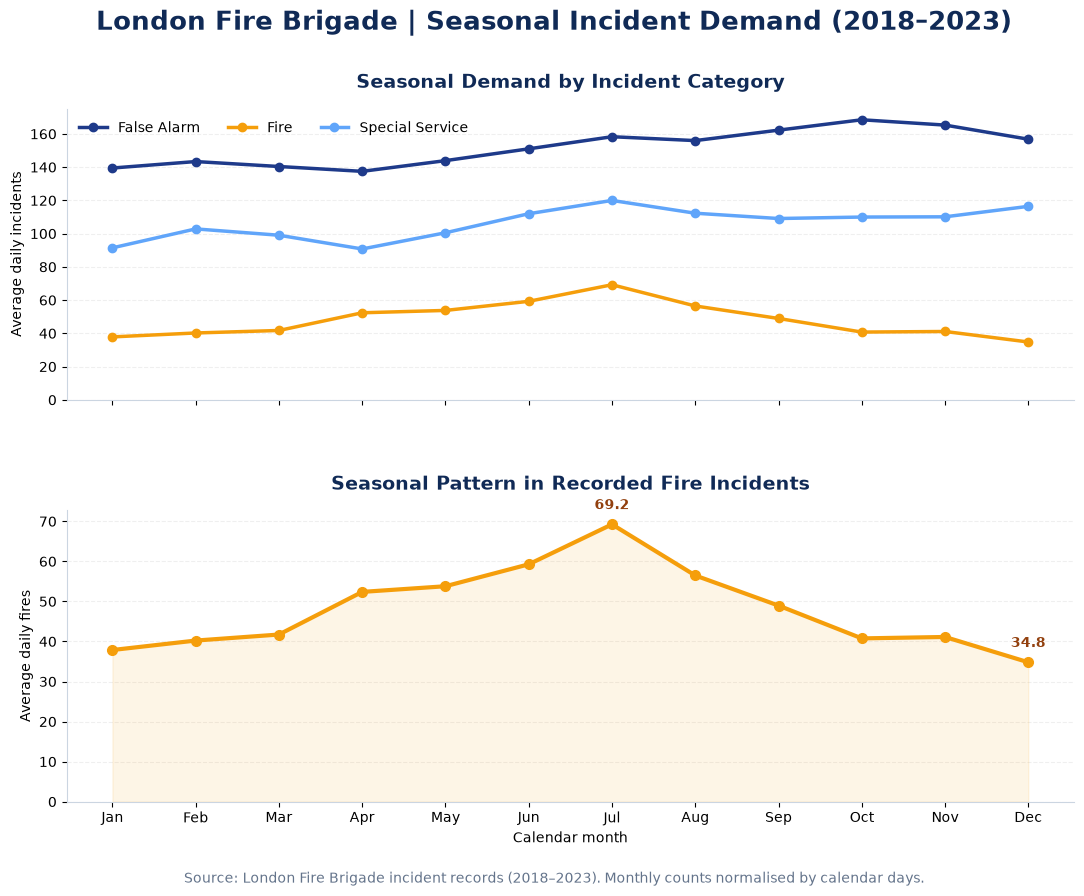

Chart saved to figures/seasonal_incident_demand.png


In [23]:
from pathlib import Path
import matplotlib.pyplot as plt

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


colours = {
    "False Alarm": "#1E3A8A",
    "Fire": "#F59E0B",
    "Special Service": "#60A5FA"
}

months = monthly_daily_average.index.tolist()
x = range(len(months))

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True,
    gridspec_kw={"hspace": 0.38}
)


for category in ["False Alarm", "Fire", "Special Service"]:
    axes[0].plot(
        x,
        monthly_daily_average[category],
        marker="o",
        markersize=6,
        linewidth=2.5,
        color=colours[category],
        label=category
    )

axes[0].set_title(
    "Seasonal Demand by Incident Category",
    fontsize=14,
    fontweight="bold",
    color="#102A56",
    pad=15
)

axes[0].set_ylabel("Average daily incidents")
axes[0].legend(frameon=False, ncol=3, loc="upper left")
axes[0].set_ylim(bottom=0)


fire_values = monthly_daily_average["Fire"].to_numpy()

axes[1].plot(
    x,
    fire_values,
    marker="o",
    markersize=7,
    linewidth=3,
    color=colours["Fire"]
)

axes[1].fill_between(
    x,
    fire_values,
    color=colours["Fire"],
    alpha=0.10
)


peak_idx = fire_values.argmax()
low_idx = fire_values.argmin()

for idx in [peak_idx, low_idx]:
    axes[1].annotate(
        f"{fire_values[idx]:.1f}",
        (idx, fire_values[idx]),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color="#92400E"
    )

axes[1].set_title(
    "Seasonal Pattern in Recorded Fire Incidents",
    fontsize=14,
    fontweight="bold",
    color="#102A56",
    pad=15
)

axes[1].set_ylabel("Average daily fires")
axes[1].set_xlabel("Calendar month")
axes[1].set_ylim(bottom=0)


for ax in axes:
    ax.set_xticks(list(x))
    ax.set_xticklabels(months)

    ax.grid(axis="y", linestyle="--", alpha=0.2)
    ax.set_axisbelow(True)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    ax.spines["left"].set_color("#CBD5E1")
    ax.spines["bottom"].set_color("#CBD5E1")

fig.suptitle(
    "London Fire Brigade | Seasonal Incident Demand (2018–2023)",
    fontsize=19,
    fontweight="bold",
    color="#102A56",
    y=0.99
)

fig.text(
    0.5, 0.02,
    "Source: London Fire Brigade incident records (2018–2023). "
    "Monthly counts normalised by calendar days.",
    ha="center",
    fontsize=10,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.055, 1, 0.95])

fig.savefig(
    figures_dir / "seasonal_incident_demand.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to figures/seasonal_incident_demand.png")


In [24]:
hourly_counts = (
    complete_years
    .groupby(["Hour", "IncidentGroup"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(24), fill_value=0)
)


total_days = (
    pd.Timestamp("2024-01-01")
    - pd.Timestamp("2018-01-01")
).days


hourly_daily_average = hourly_counts / total_days


hourly_daily_average["Total"] = (
    hourly_daily_average.sum(axis=1)
)

print("Average daily incidents by hour:")
display(hourly_daily_average.round(2))

print("\nPeak hour for each incident category:")

for category in ["Fire", "False Alarm", "Special Service", "Total"]:
    peak_hour = hourly_daily_average[category].idxmax()
    peak_value = hourly_daily_average[category].max()

    print(
        f"{category}: {peak_hour:02d}:00–{peak_hour+1:02d}:00 "
        f"({peak_value:.2f} incidents/day)"
    )


Average daily incidents by hour:


IncidentGroup,False Alarm,Fire,Special Service,Total
Hour,,,,
0,4.60,1.70,3.80,10.10
1,3.87,1.34,2.97,8.18
2,3.27,1.09,2.51,6.88
3,2.98,0.92,2.19,6.09
4,2.67,0.79,2.05,5.50
5,2.73,0.71,1.79,5.23
6,3.30,0.77,1.82,5.90
7,4.52,0.95,2.73,8.20
8,6.11,1.15,3.51,10.77



Peak hour for each incident category:
Fire: 18:00–19:00 (3.53 incidents/day)
False Alarm: 11:00–12:00 (8.68 incidents/day)
Special Service: 17:00–18:00 (6.60 incidents/day)
Total: 18:00–19:00 (18.60 incidents/day)


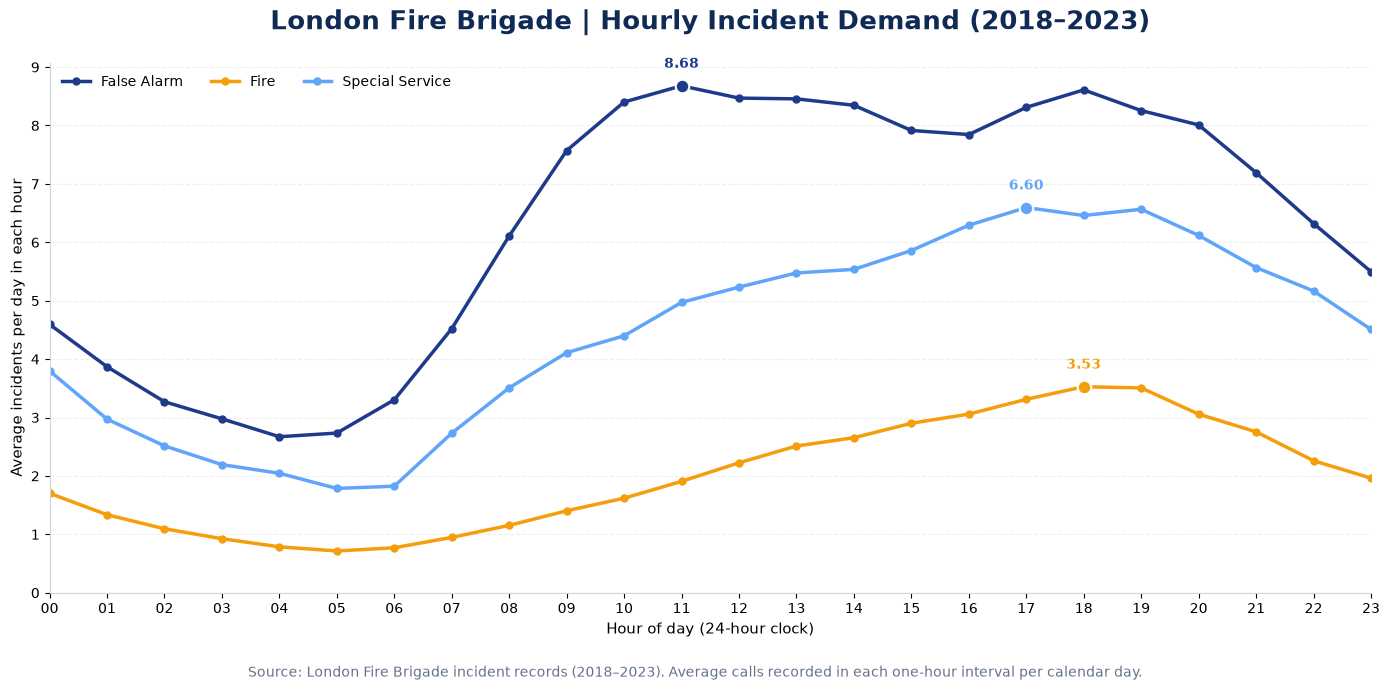

Chart saved to figures/hourly_incident_demand.png


In [25]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

colours = {
    "False Alarm": "#1E3A8A",
    "Fire": "#F59E0B",
    "Special Service": "#60A5FA"
}

fig, ax = plt.subplots(figsize=(14, 7))


for category in ["False Alarm", "Fire", "Special Service"]:

    ax.plot(
        hourly_daily_average.index,
        hourly_daily_average[category],
        marker="o",
        markersize=5,
        linewidth=2.5,
        color=colours[category],
        label=category
    )


for category in ["False Alarm", "Fire", "Special Service"]:

    peak_hour = hourly_daily_average[category].idxmax()
    peak_value = hourly_daily_average[category].max()

    ax.scatter(
        peak_hour,
        peak_value,
        color=colours[category],
        s=95,
        edgecolor="white",
        linewidth=1.5,
        zorder=5
    )

    ax.annotate(
        f"{peak_value:.2f}",
        xy=(peak_hour, peak_value),
        xytext=(0, 13),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=colours[category]
    )


ax.set_title(
    "London Fire Brigade | Hourly Incident Demand (2018–2023)",
    fontsize=19,
    fontweight="bold",
    color="#102A56",
    pad=24
)

ax.set_xlabel("Hour of day (24-hour clock)", fontsize=11)
ax.set_ylabel("Average incidents per day in each hour", fontsize=11)

ax.set_xticks(range(24))
ax.set_xticklabels([f"{hour:02d}" for hour in range(24)])

ax.set_xlim(0, 23)
ax.set_ylim(bottom=0)

ax.yaxis.set_major_locator(MultipleLocator(1))

ax.legend(
    loc="upper left",
    frameon=False,
    ncol=3,
    fontsize=10
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.20
)

ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.spines["left"].set_color("#CBD5E1")
ax.spines["bottom"].set_color("#CBD5E1")

fig.text(
    0.5, 0.025,
    "Source: London Fire Brigade incident records (2018–2023). "
    "Average calls recorded in each one-hour interval per calendar day.",
    ha="center",
    fontsize=10,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

fig.savefig(
    figures_dir / "hourly_incident_demand.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to figures/hourly_incident_demand.png")


In [26]:
resource_by_group = (
    lfb_classified
    .groupby("IncidentGroup")
    .agg(
        Incidents=("IncidentNumber", "count"),
        Total_Pump_Hours=("RecordedPumpHours", "sum"),
        Mean_Pump_Hours=("RecordedPumpHours", "mean"),
        Median_Pump_Hours=("RecordedPumpHours", "median"),

    )
)


resource_by_group["Incident_Share_Pct"] = (
    resource_by_group["Incidents"]
    / resource_by_group["Incidents"].sum()
    * 100
)


resource_by_group["Pump_Hour_Share_Pct"] = (
    resource_by_group["Total_Pump_Hours"]
    / resource_by_group["Total_Pump_Hours"].sum()
    * 100
)


resource_by_group["Resource_Share_Difference_Pp"] = (
    resource_by_group["Pump_Hour_Share_Pct"]
    - resource_by_group["Incident_Share_Pct"]
)

print("Resource utilisation by incident group:")
display(
    resource_by_group.sort_values(
        "Total_Pump_Hours", ascending=False
    ).round(2)
)

print("\nTotal recorded pump-hours:")
print(f"{lfb_classified['RecordedPumpHours'].sum():,.2f}")


Resource utilisation by incident group:


,Incidents,Total_Pump_Hours,Mean_Pump_Hours,Median_Pump_Hours,Incident_Share_Pct,Pump_Hour_Share_Pct,Resource_Share_Difference_Pp
IncidentGroup,,,,,,,
False Alarm,381223,398093.78,1.04,1.0,49.43,40.42,-9.00
Special Service,272187,314321.95,1.15,1.0,35.29,31.92,-3.37
Fire,117895,272392.90,2.31,1.0,15.29,27.66,12.37



Total recorded pump-hours:
984,808.63


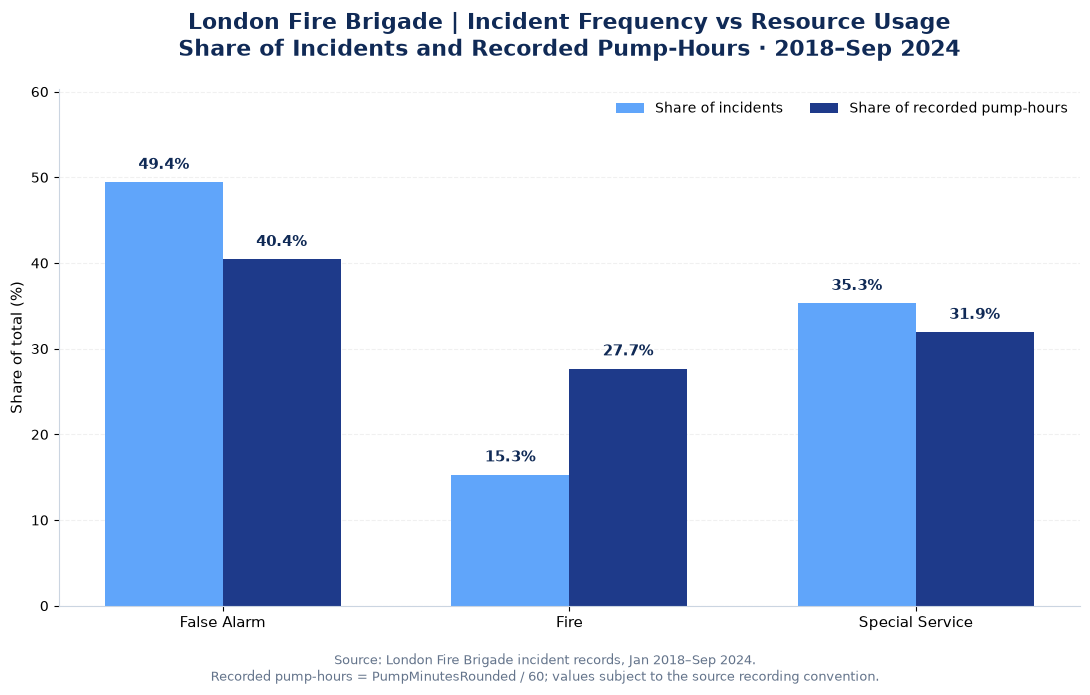

Chart saved to figures/incident_vs_pump_hours.png


In [27]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np


figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


categories = ["False Alarm", "Fire", "Special Service"]

chart_data = resource_by_group.loc[categories]

incident_share = chart_data["Incident_Share_Pct"].to_numpy()
pump_hour_share = chart_data["Pump_Hour_Share_Pct"].to_numpy()


x = np.arange(len(categories))
width = 0.34


fig, ax = plt.subplots(figsize=(11, 7))

bars_incidents = ax.bar(
    x - width / 2,
    incident_share,
    width,
    label="Share of incidents",
    color="#60A5FA"
)

bars_pump_hours = ax.bar(
    x + width / 2,
    pump_hour_share,
    width,
    label="Share of recorded pump-hours",
    color="#1E3A8A"
)


for bars in [bars_incidents, bars_pump_hours]:
    for bar in bars:
        height = bar.get_height()

        ax.annotate(
            f"{height:.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color="#102A56"
        )


ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11)

ax.set_ylabel("Share of total (%)", fontsize=11)

ax.set_title(
    "London Fire Brigade | Incident Frequency vs Resource Usage\n"
    "Share of Incidents and Recorded Pump-Hours · 2018–Sep 2024",
    fontsize=16,
    fontweight="bold",
    color="#102A56",
    pad=24
)

ax.set_ylim(
    0,
    max(incident_share.max(), pump_hour_share.max()) * 1.22
)

ax.legend(
    frameon=False,
    ncol=2,
    loc="upper right"
)

ax.grid(axis="y", linestyle="--", alpha=0.18)
ax.set_axisbelow(True)

for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

ax.spines["left"].set_color("#CBD5E1")
ax.spines["bottom"].set_color("#CBD5E1")


fig.text(
    0.5, 0.02,
    "Source: London Fire Brigade incident records, Jan 2018–Sep 2024.\n"
    "Recorded pump-hours = PumpMinutesRounded / 60; "
    "values subject to the source recording convention.",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.07, 1, 1])


fig.savefig(
    figures_dir / "incident_vs_pump_hours.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to figures/incident_vs_pump_hours.png")


In [28]:
property_resource = (
    lfb_classified
    .dropna(subset=["PropertyCategory"])
    .groupby("PropertyCategory")
    .agg(
        Incidents=("IncidentNumber", "count"),
        Total_Pump_Hours=("RecordedPumpHours", "sum"),
        Mean_Pump_Hours=("RecordedPumpHours", "mean"),
        Median_Pump_Hours=("RecordedPumpHours", "median")
    )
)


property_resource["Pump_Hour_Share_Pct"] = (
    property_resource["Total_Pump_Hours"]
    / property_resource["Total_Pump_Hours"].sum()
    * 100
)


property_resource = property_resource.sort_values(
    "Total_Pump_Hours",
    ascending=False
)

print("Recorded resource usage by property category:")
display(property_resource.round(2))

print("\nTop 10 property categories by average recorded pump-hours")
print("(Minimum 100 incidents to avoid very small groups):")

display(
    property_resource[
        property_resource["Incidents"] >= 100
    ]
    .sort_values("Mean_Pump_Hours", ascending=False)
    .head(10)
    .round(2)
)


Recorded resource usage by property category:


,Incidents,Total_Pump_Hours,Mean_Pump_Hours,Median_Pump_Hours,Pump_Hour_Share_Pct
PropertyCategory,,,,,
Dwelling,423198,526195.88,1.24,1.00,53.43
Non Residential,161603,226281.77,1.40,1.00,22.98
Outdoor,60212,81665.52,1.36,1.00,8.29
Road Vehicle,50094,61017.77,1.22,1.00,6.20
Other Residential,39893,44867.47,1.12,1.00,4.56
Outdoor Structure,34833,41781.52,1.20,1.00,4.24
Rail Vehicle,633,1342.93,2.12,1.62,0.14
Boat,408,951.10,2.33,1.20,0.10
Aircraft,431,704.68,1.63,1.12,0.07



Top 10 property categories by average recorded pump-hours
(Minimum 100 incidents to avoid very small groups):


,Incidents,Total_Pump_Hours,Mean_Pump_Hours,Median_Pump_Hours,Pump_Hour_Share_Pct
PropertyCategory,,,,,
Boat,408,951.10,2.33,1.20,0.10
Rail Vehicle,633,1342.93,2.12,1.62,0.14
Aircraft,431,704.68,1.63,1.12,0.07
Non Residential,161603,226281.77,1.40,1.00,22.98
Outdoor,60212,81665.52,1.36,1.00,8.29
Dwelling,423198,526195.88,1.24,1.00,53.43
Road Vehicle,50094,61017.77,1.22,1.00,6.20
Outdoor Structure,34833,41781.52,1.20,1.00,4.24
Other Residential,39893,44867.47,1.12,1.00,4.56


C:\Users\Rakeen Afser\AppData\Local\Temp\ipykernel_16184\1039198854.py:127: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


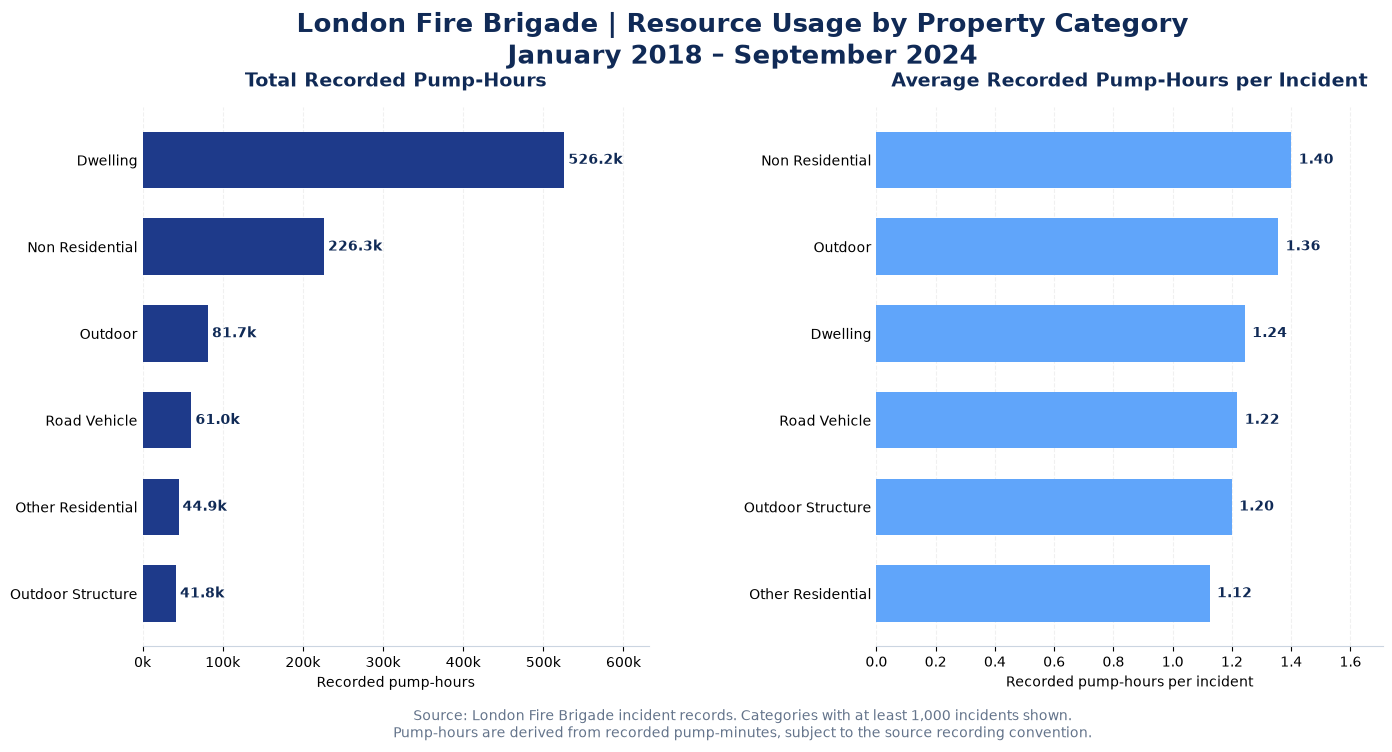

Chart saved to figures/property_resource_utilisation.png


In [29]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


plot_data = property_resource[
    property_resource["Incidents"] >= 1000
].copy()


total_data = plot_data.sort_values("Total_Pump_Hours")
average_data = plot_data.sort_values("Mean_Pump_Hours")

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7),
    gridspec_kw={"wspace": 0.45}
)





axes[0].barh(
    total_data.index,
    total_data["Total_Pump_Hours"],
    color="#1E3A8A",
    height=0.65
)

for i, value in enumerate(total_data["Total_Pump_Hours"]):
    axes[0].text(
        value + 5000,
        i,
        f"{value / 1000:,.1f}k",
        va="center",
        fontsize=10,
        color="#102A56",
        fontweight="bold"
    )

axes[0].set_title(
    "Total Recorded Pump-Hours",
    fontsize=14,
    fontweight="bold",
    color="#102A56",
    pad=15
)

axes[0].set_xlabel("Recorded pump-hours")
axes[0].set_xlim(0, total_data["Total_Pump_Hours"].max() * 1.20)

axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1000:,.0f}k")
)





axes[1].barh(
    average_data.index,
    average_data["Mean_Pump_Hours"],
    color="#60A5FA",
    height=0.65
)

for i, value in enumerate(average_data["Mean_Pump_Hours"]):
    axes[1].text(
        value + 0.025,
        i,
        f"{value:.2f}",
        va="center",
        fontsize=10,
        color="#102A56",
        fontweight="bold"
    )

axes[1].set_title(
    "Average Recorded Pump-Hours per Incident",
    fontsize=14,
    fontweight="bold",
    color="#102A56",
    pad=15
)

axes[1].set_xlabel("Recorded pump-hours per incident")
axes[1].set_xlim(0, average_data["Mean_Pump_Hours"].max() * 1.22)





for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.18)
    ax.set_axisbelow(True)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#CBD5E1")
    ax.tick_params(axis="y", length=0)

fig.suptitle(
    "London Fire Brigade | Resource Usage by Property Category\n"
    "January 2018 – September 2024",
    fontsize=19,
    fontweight="bold",
    color="#102A56",
    y=1.02
)

fig.text(
    0.5, -0.02,
    "Source: London Fire Brigade incident records. "
    "Categories with at least 1,000 incidents shown.\n"
    "Pump-hours are derived from recorded pump-minutes, "
    "subject to the source recording convention.",
    ha="center",
    fontsize=10,
    color="#64748B"
)

plt.tight_layout()

fig.savefig(
    figures_dir / "property_resource_utilisation.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to figures/property_resource_utilisation.png")


In [30]:
borough_totals = (
    lfb_classified
    .groupby("IncGeo_BoroughName")
    .agg(
        Total_Incidents=("IncidentNumber", "count")
    )
)


false_alarms = lfb_classified[
    lfb_classified["IncidentGroup"] == "False Alarm"
].copy()


false_alarm_borough = (
    false_alarms
    .groupby("IncGeo_BoroughName")
    .agg(
        False_Alarms=("IncidentNumber", "count"),
        Recorded_Pump_Hours=("RecordedPumpHours", "sum"),

    )
)


false_alarm_borough = borough_totals.join(
    false_alarm_borough,
    how="left"
)


false_alarm_borough["False_Alarm_Share_Pct"] = (
    false_alarm_borough["False_Alarms"]
    / false_alarm_borough["Total_Incidents"]
    * 100
)



false_alarm_borough = false_alarm_borough.sort_values(
    "False_Alarms",
    ascending=False
)

print("Top 10 boroughs by recorded false-alarm volume:")
display(false_alarm_borough.head(10).round(2))

print("\nTop 10 boroughs by false-alarm percentage:")
display(
    false_alarm_borough
    .sort_values("False_Alarm_Share_Pct", ascending=False)
    .head(10)
    .round(2)
)


assert (
    false_alarm_borough["False_Alarms"].sum()
    == len(false_alarms)
), "False-alarm counts do not reconcile."

print("\nValidation passed: borough totals match all false-alarm records.")


Top 10 boroughs by recorded false-alarm volume:


,Total_Incidents,False_Alarms,Recorded_Pump_Hours,False_Alarm_Share_Pct
IncGeo_BoroughName,,,,
WESTMINSTER,55847,36879,38269.65,66.04
CAMDEN,34135,19992,20756.70,58.57
SOUTHWARK,33395,15832,16671.67,47.41
LAMBETH,32673,15421,16030.52,47.20
KENSINGTON AND CHELSEA,25734,15245,15637.25,59.24
TOWER HAMLETS,33171,14679,15982.45,44.25
CROYDON,31725,14631,15326.78,46.12
HACKNEY,30264,13406,14175.02,44.30
LEWISHAM,27926,13289,13820.85,47.59



Top 10 boroughs by false-alarm percentage:


,Total_Incidents,False_Alarms,Recorded_Pump_Hours,False_Alarm_Share_Pct
IncGeo_BoroughName,,,,
CITY OF LONDON,7663,6022,6305.90,78.59
WESTMINSTER,55847,36879,38269.65,66.04
KENSINGTON AND CHELSEA,25734,15245,15637.25,59.24
CAMDEN,34135,19992,20756.70,58.57
HAMMERSMITH AND FULHAM,21831,12579,12957.93,57.62
RICHMOND UPON THAMES,12429,6916,7072.25,55.64
SUTTON,13370,7051,7337.17,52.74
KINGSTON UPON THAMES,10190,5317,5479.13,52.18
WANDSWORTH,23566,12130,12780.85,51.47



Validation passed: borough totals match all false-alarm records.


C:\Users\Rakeen Afser\AppData\Local\Temp\ipykernel_16184\3683012248.py:121: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.05, 1, 0.96])


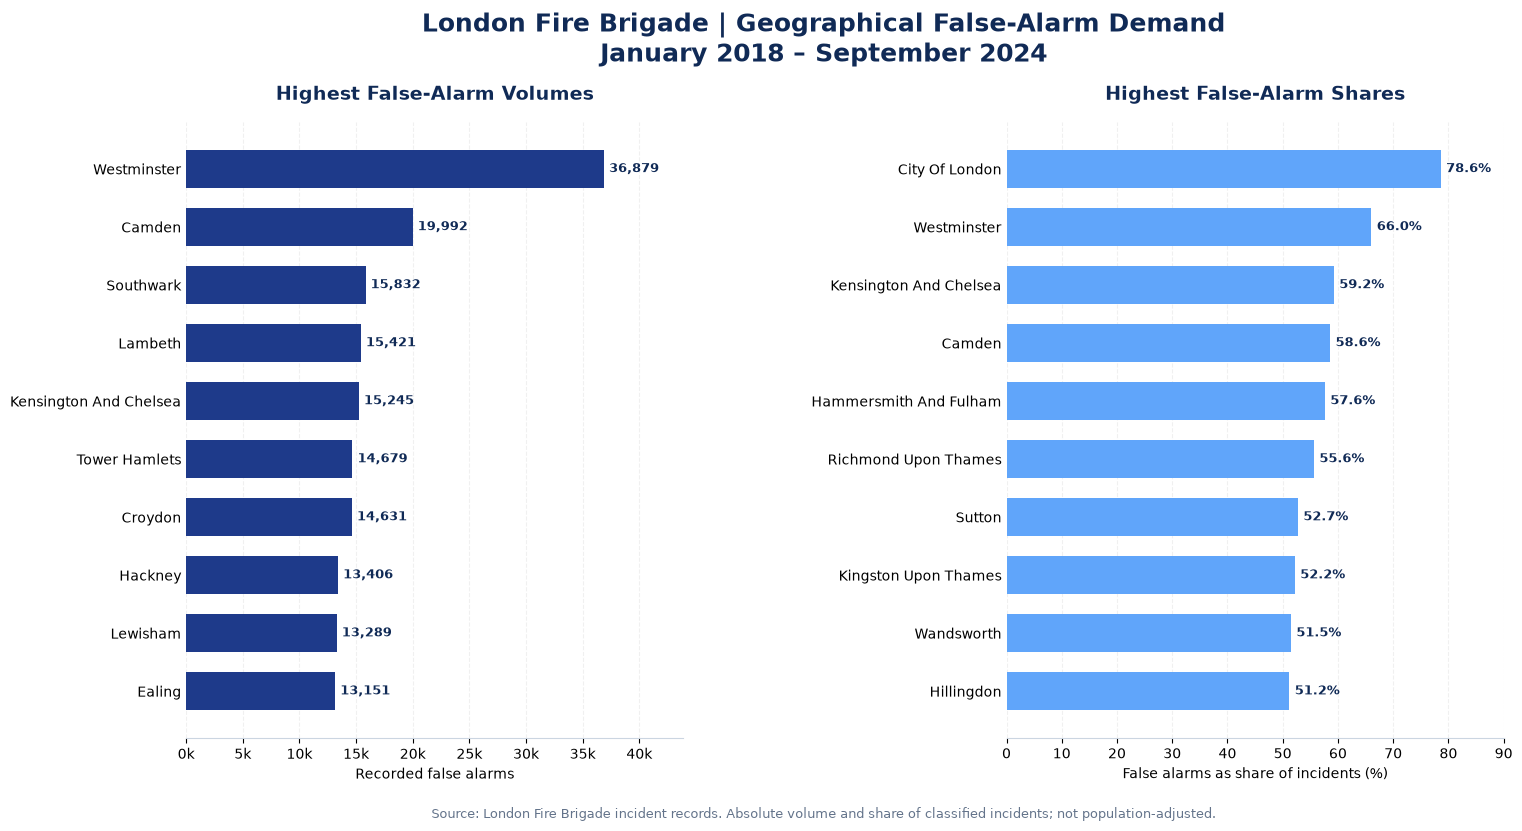

Chart saved to figures/false_alarm_borough_comparison.png


In [31]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)


volume_data = (
    false_alarm_borough
    .nlargest(10, "False_Alarms")
    .sort_values("False_Alarms")
)

share_data = (
    false_alarm_borough
    .nlargest(10, "False_Alarm_Share_Pct")
    .sort_values("False_Alarm_Share_Pct")
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 8),
    gridspec_kw={"wspace": 0.65}
)


axes[0].barh(
    volume_data.index.str.title(),
    volume_data["False_Alarms"],
    color="#1E3A8A",
    height=0.65
)

for i, value in enumerate(volume_data["False_Alarms"]):
    axes[0].text(
        value + 450,
        i,
        f"{value:,}",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#102A56"
    )

axes[0].set_title(
    "Highest False-Alarm Volumes",
    fontsize=14,
    fontweight="bold",
    color="#102A56",
    pad=16
)

axes[0].set_xlabel("Recorded false alarms")
axes[0].set_xlim(0, volume_data["False_Alarms"].max() * 1.19)

axes[0].xaxis.set_major_formatter(
    FuncFormatter(lambda x, pos: f"{x / 1000:.0f}k")
)


axes[1].barh(
    share_data.index.str.title(),
    share_data["False_Alarm_Share_Pct"],
    color="#60A5FA",
    height=0.65
)

for i, value in enumerate(share_data["False_Alarm_Share_Pct"]):
    axes[1].text(
        value + 1,
        i,
        f"{value:.1f}%",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#102A56"
    )

axes[1].set_title(
    "Highest False-Alarm Shares",
    fontsize=14,
    fontweight="bold",
    color="#102A56",
    pad=16
)

axes[1].set_xlabel("False alarms as share of incidents (%)")
axes[1].set_xlim(0, 90)


for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.18)
    ax.set_axisbelow(True)
    ax.tick_params(axis="y", length=0)

    for spine in ["top", "right", "left"]:
        ax.spines[spine].set_visible(False)

    ax.spines["bottom"].set_color("#CBD5E1")

fig.suptitle(
    "London Fire Brigade | Geographical False-Alarm Demand\n"
    "January 2018 – September 2024",
    fontsize=18,
    fontweight="bold",
    color="#102A56",
    y=1.02
)

fig.text(
    0.5, 0.01,
    "Source: London Fire Brigade incident records. "
    "Absolute volume and share of classified incidents; "
    "not population-adjusted.",
    ha="center",
    fontsize=9,
    color="#64748B"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.96])

fig.savefig(
    figures_dir / "false_alarm_borough_comparison.png",
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Chart saved to figures/false_alarm_borough_comparison.png")


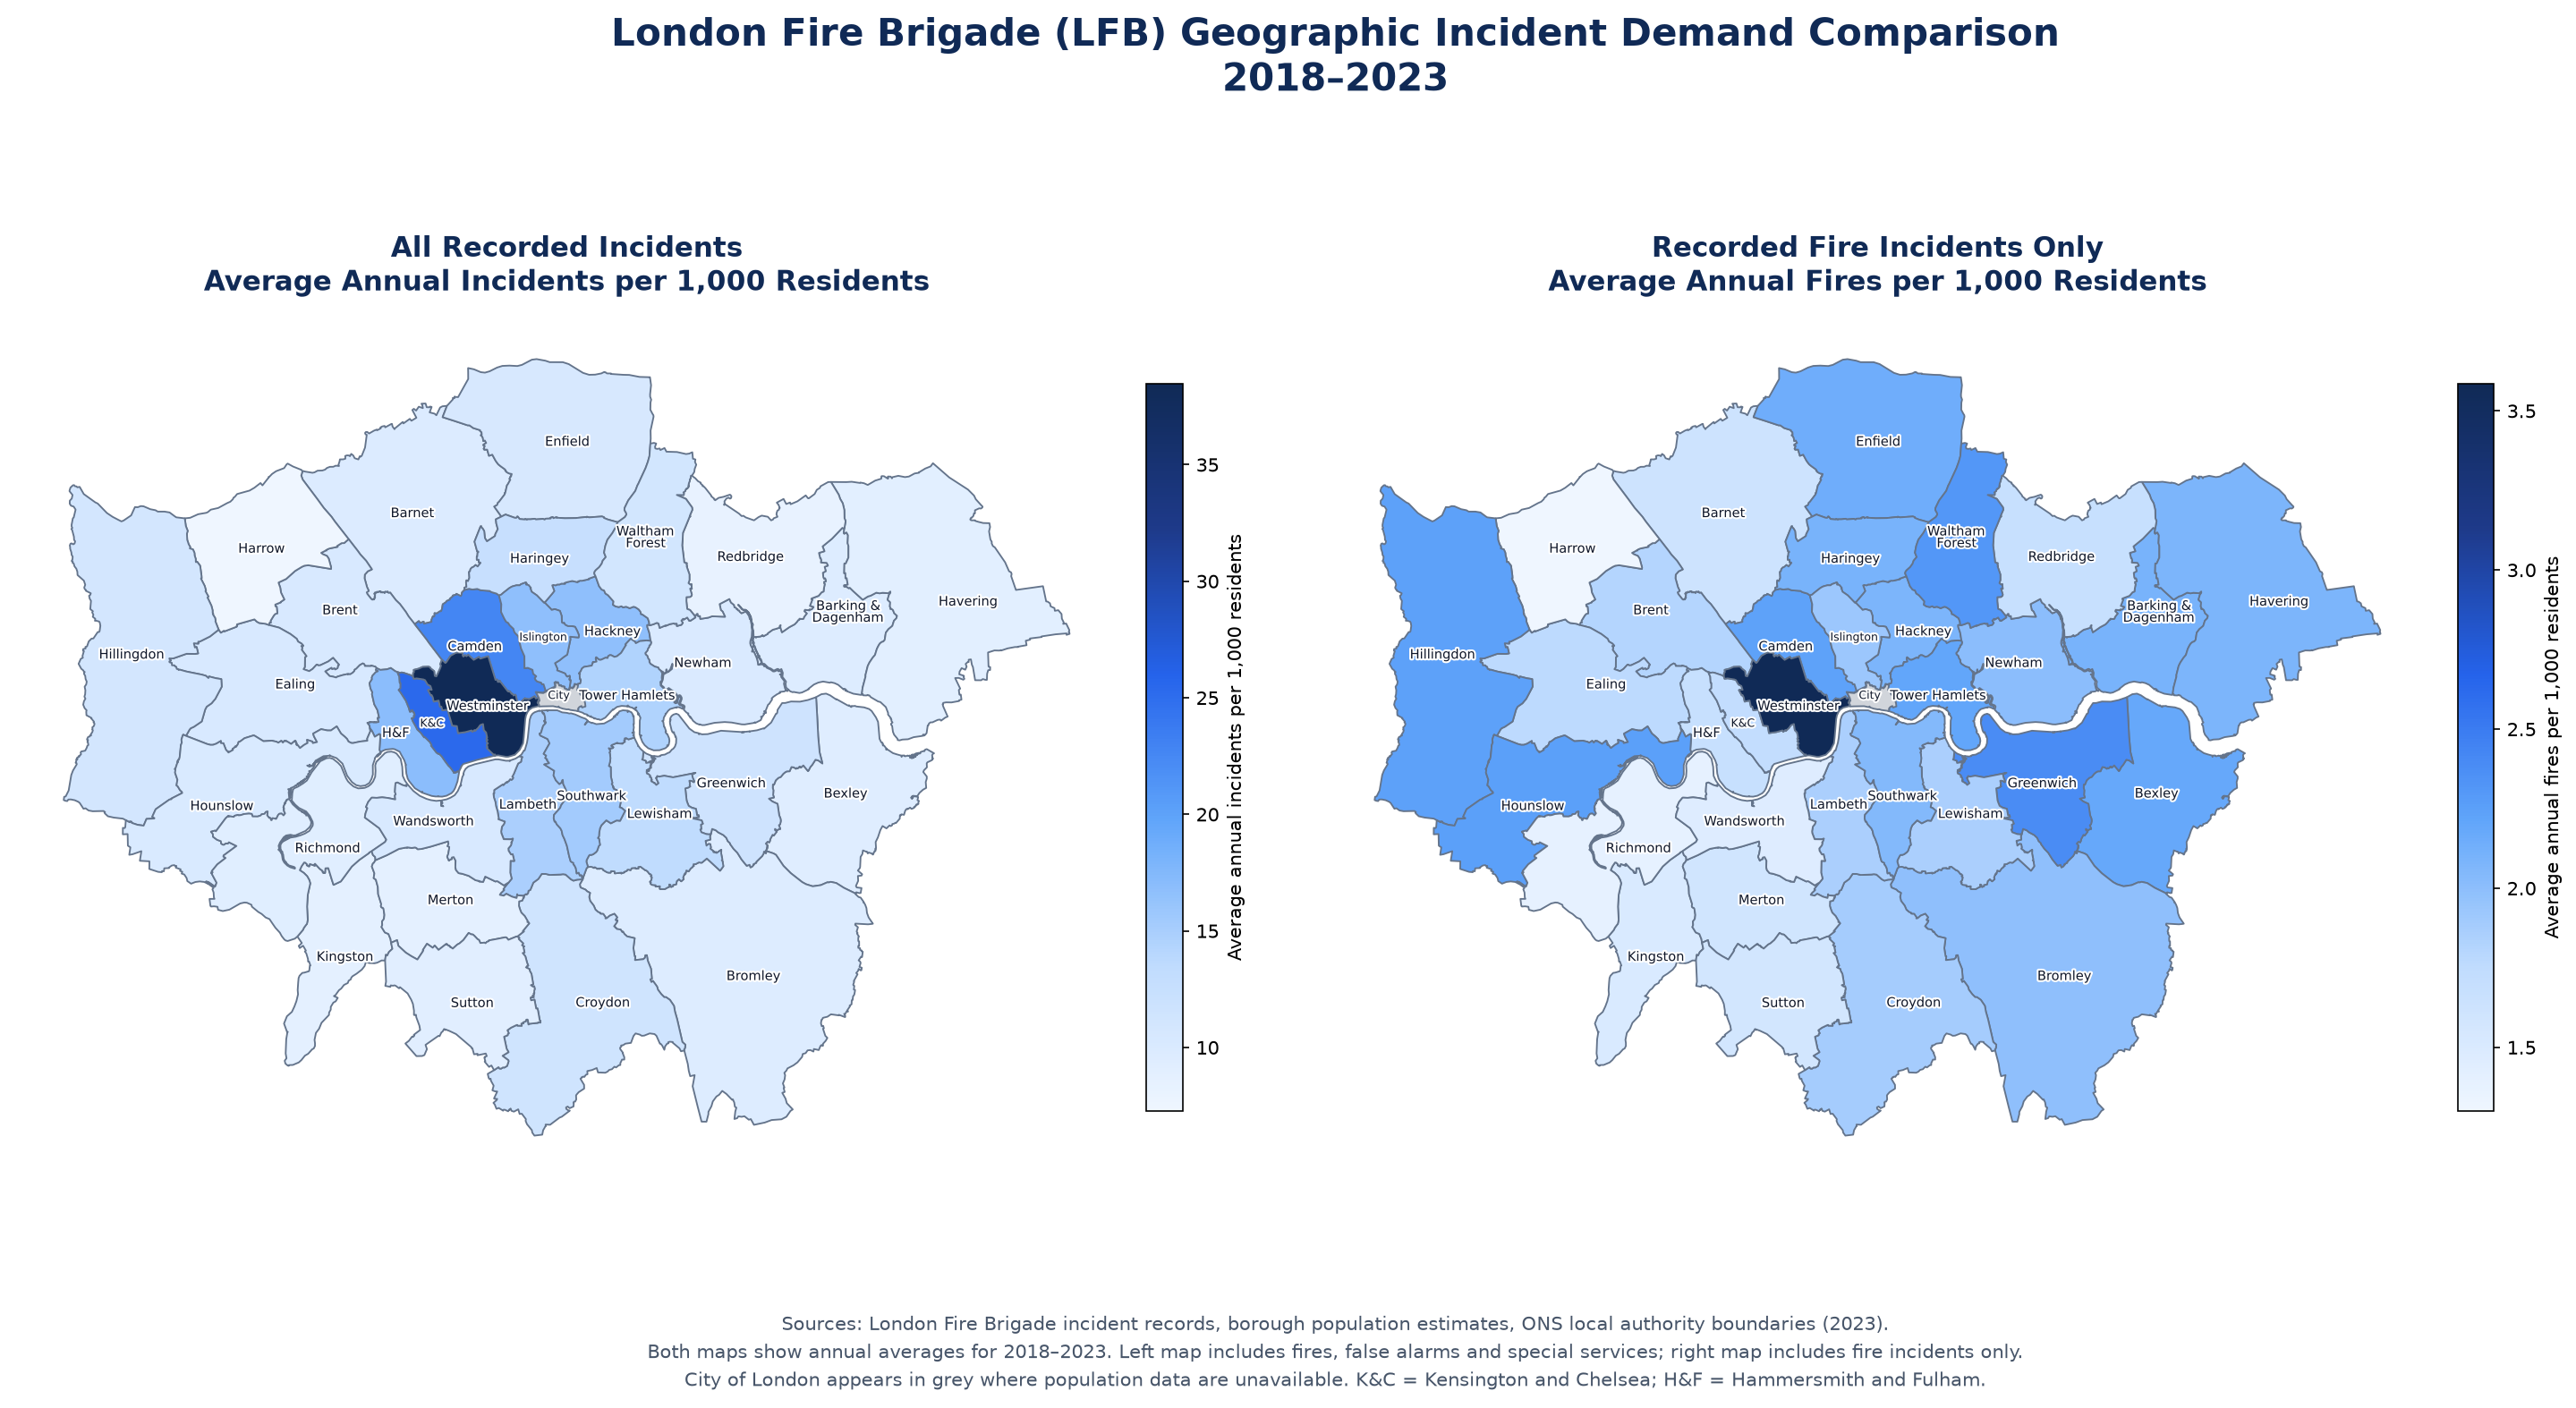

Saved: figures\london_side_by_side_map_comparison.png


In [34]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap

years_count = 6

all_incidents_borough = (
    complete_years
    .groupby("IncGeo_BoroughName")
    .agg(Total_Incidents=("IncidentNumber", "count"))
    .reset_index()
)

all_incidents_borough = all_incidents_borough.merge(
    population_clean,
    left_on="IncGeo_BoroughName",
    right_on="BoroughName",
    how="left",
    validate="one_to_one"
)

all_incidents_borough["Incidents_per_1000"] = (
    all_incidents_borough["Total_Incidents"] / years_count
    / all_incidents_borough["Population"]
    * 1000
)

all_incident_map = london_boundaries.merge(
    all_incidents_borough[
        ["IncGeo_BoroughName", "Total_Incidents", "Incidents_per_1000"]
    ],
    left_on="BoroughName",
    right_on="IncGeo_BoroughName",
    how="left",
    validate="one_to_one"
)

fire_incidents_2018_2023 = complete_years[
    complete_years["IncidentGroup"] == "Fire"
].copy()

fire_borough = (
    fire_incidents_2018_2023
    .groupby("IncGeo_BoroughName")
    .agg(Fire_Incidents=("IncidentNumber", "count"))
    .reset_index()
)

fire_borough = fire_borough.merge(
    population_clean,
    left_on="IncGeo_BoroughName",
    right_on="BoroughName",
    how="left",
    validate="one_to_one"
)

fire_borough["Fires_per_1000"] = (
    fire_borough["Fire_Incidents"] / years_count
    / fire_borough["Population"]
    * 1000
)

fire_map = london_boundaries.merge(
    fire_borough[
        ["IncGeo_BoroughName", "Fire_Incidents", "Fires_per_1000"]
    ],
    left_on="BoroughName",
    right_on="IncGeo_BoroughName",
    how="left",
    validate="one_to_one"
)

figures_dir = Path("figures")
figures_dir.mkdir(exist_ok=True)

blue_cmap = LinearSegmentedColormap.from_list(
    "LondonBlue",
    ["#EFF6FF", "#BFDBFE", "#60A5FA", "#2563EB", "#1E3A8A", "#102A56"]
)

short_names = {
    "KENSINGTON AND CHELSEA": "K&C",
    "HAMMERSMITH AND FULHAM": "H&F",
    "BARKING AND DAGENHAM": "Barking &\nDagenham",
    "KINGSTON UPON THAMES": "Kingston",
    "RICHMOND UPON THAMES": "Richmond",
    "CITY OF LONDON": "City",
    "WALTHAM FOREST": "Waltham\nForest"
}

fig, axes = plt.subplots(1, 2, figsize=(20, 11), dpi=150)

all_incident_map.plot(
    column="Incidents_per_1000",
    cmap=blue_cmap,
    linewidth=0.9,
    edgecolor="#64748B",
    legend=True,
    legend_kwds={
        "label": "Average annual incidents per 1,000 residents",
        "shrink": 0.65,
        "pad": 0.02
    },
    missing_kwds={
        "color": "#D1D5DB",
        "edgecolor": "#64748B"
    },
    ax=axes[0]
)

fire_map.plot(
    column="Fires_per_1000",
    cmap=blue_cmap,
    linewidth=0.9,
    edgecolor="#64748B",
    legend=True,
    legend_kwds={
        "label": "Average annual fires per 1,000 residents",
        "shrink": 0.65,
        "pad": 0.02
    },
    missing_kwds={
        "color": "#D1D5DB",
        "edgecolor": "#64748B"
    },
    ax=axes[1]
)

for ax, gdf in zip(axes, [all_incident_map, fire_map]):
    for _, borough in gdf.iterrows():
        point = borough.geometry.representative_point()
        name = short_names.get(borough["BoroughName"], borough["BoroughName"].title())
        area = borough.geometry.area
        fontsize = 6 if area < 15_000_000 else 7

        ax.text(
            point.x,
            point.y,
            name,
            fontsize=fontsize,
            ha="center",
            va="center",
            color="#0F172A",
            linespacing=0.9,
            path_effects=[pe.withStroke(linewidth=2, foreground="white")],
            zorder=5
        )

    ax.set_axis_off()

axes[0].set_title(
    "All Recorded Incidents\nAverage Annual Incidents per 1,000 Residents",
    fontsize=15,
    fontweight="bold",
    color="#102A56",
    pad=16
)

axes[1].set_title(
    "Recorded Fire Incidents Only\nAverage Annual Fires per 1,000 Residents",
    fontsize=15,
    fontweight="bold",
    color="#102A56",
    pad=16
)

fig.suptitle(
    "London Fire Brigade (LFB) Geographic Incident Demand Comparison\n2018–2023",
    fontsize=20,
    fontweight="bold",
    color="#102A56",
    y=0.97
)

fig.text(
    0.5, 0.04,
    "Sources: London Fire Brigade incident records, borough population estimates, ONS local authority boundaries (2023).\n"
    "Both maps show annual averages for 2018–2023. Left map includes fires, false alarms and special services; right map includes fire incidents only.\n"
    "City of London appears in grey where population data are unavailable. K&C = Kensington and Chelsea; H&F = Hammersmith and Fulham.",
    ha="center",
    fontsize=10,
    color="#475569",
    linespacing=1.5
)

plt.tight_layout(rect=[0, 0.08, 1, 0.94])

output_path = figures_dir / "london_side_by_side_map_comparison.png"

fig.savefig(
    output_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Saved: {output_path}")

In [35]:
from pathlib import Path

project = Path.cwd()

print("Current folder:", project)
print("\nProject files:")

for file in sorted(project.rglob("*")):
    if file.is_file() and ".ipynb_checkpoints" not in file.parts:
        print(file.relative_to(project))

Current folder: C:\Users\Rakeen Afser\LFB-Incident-Analysis

Project files:
data\LFB2018-2024.csv
data\london_boundaries.geojson
data\LondonBoroughPopulationData.csv
figures\annual_incident_trends.png
figures\borough_incident_composition.png
figures\false_alarm_borough_comparison.png
figures\hourly_incident_demand.png
figures\incident_vs_pump_hours.png
figures\london_fire_only_map.png
figures\london_incident_demand_map.png
figures\london_side_by_side_map_comparison.png
figures\property_resource_utilisation.png
figures\seasonal_incident_demand.png
LFB_Analysis_Code_Only.ipynb
LFB_Final_Analysis.ipynb


In [36]:
from pathlib import Path

requirements = """pandas
numpy
matplotlib
geopandas
pyogrio
shapely
"""

Path("requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)

print("requirements.txt created successfully")

requirements.txt created successfully
